# Magic-state cultivation, d = 5: every fault at once

> **In short.**
> * **The problem.** Cultivation makes a T state inside a colour code. At d = 5 it starts in the [[7,1,3]] code and grows it into the [[19,1,5]] code.
> * A run is thrown away when a check fires. A *fault* is a Pauli error (X, Y or Z) right after one gate. The *fault distance* is the fewest faults that pass every check and still leave a wrong state.
> * **This circuit.** The d = 5 circuits are the largest cultivation circuits in this repository. This one has real T gates: 42 qubits, 888 gates, 53 T gates (Section 1).
> * **Why this is hard.** Stim cannot run T gates; its numbers are for S in place of T. A state-vector simulator with T gates decides one pattern of faults at a time. There are about 33 million pairs and about 88 billion triples of faults (Section 6). Other tools that handle T gates are in Section 8.
> * **Our way.** Two switches after every gate, on each of its qubits: one for an X, one for a Z. So every Pauli fault after every gate is a value of the switches (Section 3).
> * The switches are pushed to the end with Pauli rules. This gives a formula for each result, each T gate and each output (Section 5).
> * The circuit is reduced once, with the 53 T switches, the output Pauli and the results kept as variables (Section 4). A pattern of faults is then decided from its formulas, plus a small diagram when needed (Section 6).
> * **What this notebook shows.** Without faults, and when every check passes, the reduced circuit is $T^\dagger\vert+\rangle$ in the d = 5 colour code (Section 2).
> * With faults: all 8109 single faults are decided in about 87 s, and **none is wrong** (Section 6).
> * All 33 million pairs are tried too, the same fast way (`lowest_wrong(2)`), in about 118 minutes: **no pair is wrong** (Section 6).
> * Triples are not tried one by one. It is too slow: only adding up their formulas takes about 19 days on one core (Section 6).
> * **A solver** does not list patterns (Section 7). It proposes the fewest faults that *can* be wrong, and `classify` decides each proposal. In about 17 minutes it finds a **wrong set of 3 faults** in the d = 5 double-check: X on qubit 29 and X on qubit 33 (stage 6), and Y on qubit 40 (stage 7). `classify` and `classify_directly` both say wrong.
> * So with real T gates the fault distance is **3**, the value Chan et al. report: no single fault and no pair is wrong (all tried), and a set of 3 is wrong. With S in place of T it is 4.
> * The solver also rules out 2 faults on its own (an argument, not a full try). It agrees with Section 6 (Section 7).
> * **Times.** The load of the machine is printed in the first and the last cell, before and after trying every pair, and before and after the search. Other programs ran at the same time, mostly while every pair was tried (load about 6). The search of Section 7 ran at a lower load. The laptop slept during Section 6; the times count only the time it was awake.

| step | what | function | result |
|---|---|---|---|
| 1 | read the circuit | `program_from_stim`, `draw_program`, `code_at` | 42 qubits, 888 gates, 53 T gates; the [[19,1,5]] code at the end |
| 2 | reduce it, no faults | `reduce_gpf`, `check_detectors`, `in_face_variables`, `code_layout`, `draw_graph_3d` | 89 checks, the file's; 53 gadgets become 25, then one phase 7π/4 on L: when the checks pass, $T^\dagger\vert+\rangle$ in the colour code |
| 3 | two switches after every gate | `error_formulas` | 1272 places, 2544 switches; 53 T switches (sums of switches) |
| 4 | one reduction, every variable kept | `ef.reduced`, `in_face_variables`, `layout_gpf`, `draw_graph` | 148 spiders, 53 gadgets; exactly `change_variables` of `ef.reduced`, vertex by vertex |
| 5 | every equation | `formula`, `detector_switches`, `signature` | 53 T switches, 93 results, 19 outputs; 89 checks |
| 6 | decide faults, fast and slow | `classify`, `classify_directly`, `lowest_wrong` | 8109 single faults and 32822847 pairs, none wrong (about 87 s and about 118 minutes); triples not tried one by one (estimates only) |
| 7 | a solver | `branch_model`, `search_lowest_wrong`, `classify_directly`, `circuit_distance` | a wrong set of 3 faults, checked two ways (about 17 minutes, 3798 runs of the solver); fault distance 3 (the solver's "not 2" agrees with step 6); with S in place of T: 4 |

Each step below has **What we do** (plain words), the code (library calls only), and **What you see** (from the output). The pictures are also saved in `figures/cultivation_faults/`.

**What we do.** We load the library, zxqec (it uses PyZX). We print where zxqec is read from, so we know which copy runs.

We also print how busy the machine is (its *load*). Other programs that run at the same time make every time in this notebook longer.

In [1]:
%matplotlib inline
import os
import random
import textwrap
import time
from collections import Counter
from IPython.display import display
from pyzx.utils import VertexType
import zxqec
from zxqec.gpf import (boolean_variables, change_variables, evaluate_phase, is_leaf, layout_gpf, phase_polynomial,
                       reduce_gpf, same_map)
from zxqec.qprogram import check_detectors, error_formulas, program_from_stim
from zxqec.spacetime import (code_layout, draw_checks, draw_graph, draw_graph_3d, draw_program, draw_slice,
                             in_face_variables)
print("zxqec is read from", os.path.dirname(zxqec.__file__))
print("this machine has {} cores; load average now (last 1, 5, 15 minutes): {:.1f}, {:.1f}, {:.1f}".format(
    os.cpu_count(), *os.getloadavg()))
FIG = 'figures/cultivation_faults'
os.makedirs(FIG, exist_ok=True)
start = time.perf_counter()

zxqec is read from /Users/chenxi/Leiden/zx-qec/zxqec/zxqec
this machine has 10 cores; load average now (last 1, 5, 15 minutes): 5.2, 7.2, 6.0


**What you see.** zxqec is read from `/Users/chenxi/Leiden/zx-qec/zxqec/zxqec`: the working copy. The machine has 10 cores. Its load over the last minute was about 5.2 (a load of about 1 means only this notebook runs).

## 1. The circuit

**What we do.** First we print the comments at the top of each Stim file in the folder. They say what each file is and where it comes from.

Then we read the d = 5 cultivation circuit with real T gates from its Stim file (`program_from_stim`). The T gates stay T gates.

* We give the eight parts of the circuit (the *stages*) a name, as in `Cultivation.ipynb`.
* We count the gates. For each stage we list its T gates and its results.
* Some gates are *fed forward*: the circuit applies a Pauli when a result is 1. We list them.
* A reset throws away what was on its qubit. For some resets the diagram keeps that value as a variable, with a name. We list these names.
* We draw the circuit (`draw_program`). Each stage gets its own colour.

the .stim files in circuits/cultivation, with the comments at the top of each:
== d3_cultivation.stim
    d = 3 magic-state cultivation: injection, a round of checks, and the double-check.

    Copied without change from circuit_source_injection_T in d_3_circuit_definitions.py of
    https://github.com/kh428/accel-cutting-magic-state
    (Apache License 2.0), the companion code of
    K. H. Wan, Z. Zhong, A. Zapirain, "Simulating magic state cultivation with few Clifford terms",
    Quantum 10, 2134 (2026), arXiv:2509.08658,
    which follows the cultivation protocol of
    C. Gidney, N. Shutty, C. Jones, "Magic state cultivation: growing T states as cheap as CNOT
    gates", arXiv:2409.17595.
    Stim's text format, with T and T_DAG added (Stim itself cannot simulate them).
== d5_cultivation.stim
    d = 5 magic-state cultivation with real T gates: injection, the d = 3 double-check, growth to
    d = 5 with three rounds of checks, and the d = 5 double-check.

    Lines 1-465 of legacy

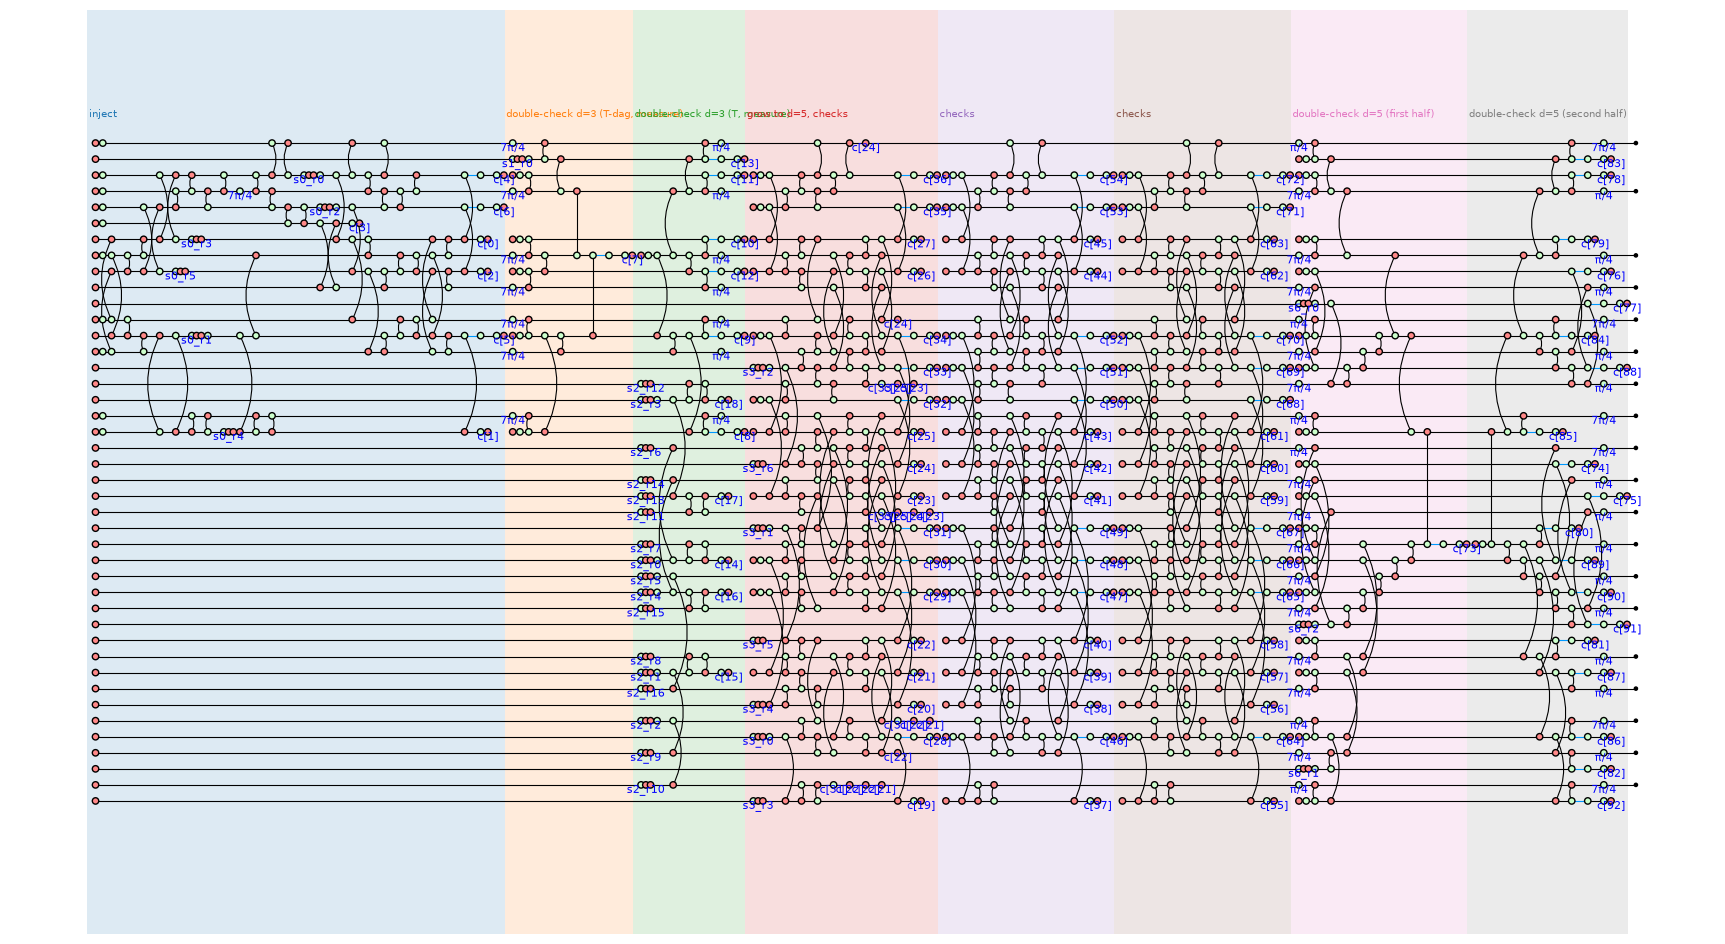

draw_program: about 1.7 s


In [2]:
print("the .stim files in circuits/cultivation, with the comments at the top of each:")
for name in sorted(name for name in os.listdir('circuits/cultivation') if name.endswith('.stim')):
    head = []
    for line in open('circuits/cultivation/' + name):
        if not line.startswith('#'):
            break
        head.append(line[1:].strip())
    print("==", name)
    print(textwrap.indent('\n'.join(head), '    '))
print()
text = open('circuits/cultivation/d5_cultivation.stim').read()
names = ['inject', 'double-check d=3 (T-dag, measure)', 'double-check d=3 (T, measure)', 'grow to d=5, checks',
         'checks', 'checks', 'double-check d=5 (first half)', 'double-check d=5 (second half)']
real, circ = program_from_stim(text, names=names)
gates = Counter(g.name for st in real.stages for g in st.circuit.gates)
print(real.qubits, "qubits;", sum(gates.values()), "gates:", dict(gates))
print("T gates (T and T-dag):", gates['T'], "; measurements:", gates['Measurement'], "; stages:", real.num_stages,
      "; DETECTOR lines in the file:", len(circ.detectors))
for s in range(real.num_stages):
    at = real.stage_circuit(s).gates
    results = [g.result_bit for g in at if g.name == 'Measurement']
    print("  stage {}: {:34s} {}".format(s, real.stage(s).name, dict(Counter(g.name for g in at))))
    print("      T-dag on qubits {}; T on qubits {}".format(
        [g.target for g in at if g.name == 'T' and g.adjoint] or 'none',
        [g.target for g in at if g.name == 'T' and not g.adjoint] or 'none'))
    print("      results: {}".format('c[{}]'.format(results[0]) if len(results) == 1
                                   else '{} results, c[{}] to c[{}]'.format(len(results), results[0], results[-1])))
fed = [(s, g) for s in range(real.num_stages) for g in real.stage_circuit(s).gates if g.name == 'ParityControlled']
print("fed-forward Paulis (a Pauli that the circuit applies when a result is 1):", len(fed), "in stages",
      sorted({s for s, g in fed}))
print(textwrap.fill(', '.join(repr(g) for s, g in fed), width=118, initial_indent='    ', subsequent_indent='    '))
whole = real.quantum_graph()
resets = sorted(v for v in boolean_variables(whole) if not v.startswith('c['))
print("{} values that resets throw away, kept as variables (in the picture as s<stage>_r<k>):".format(
    len(resets)))
print(textwrap.fill(', '.join(resets), width=118, initial_indent='    ', subsequent_indent='    '))
t0 = time.perf_counter()
fig = draw_program(real, 0, show_time=False, labels=False, figsize=(22, 12))
fig.savefig(FIG + '/d5_circuit.png', bbox_inches='tight')
display(fig)
print("draw_program: about {:.1f} s".format(time.perf_counter() - t0))

**What you see.** The folder has four `.stim` files. Their comments say what each one is:

| file | what it is |
|---|---|
| `d3_cultivation.stim` | d = 3 cultivation, with T and T_DAG |
| `d5_cultivation.stim` | d = 5 cultivation with real T gates, from the SOFT repository; it follows Gidney, Shutty and Jones |
| `d5_cultivation_gidney_s.stim` | the same d = 5 protocol as Gidney, Shutty and Jones published it, with S and S_DAG in place of T and T_DAG; the same CNOTs, resets and measurements, in the same order, as `d5_cultivation.stim` with `d5_final_check.stim` |
| `d5_final_check.stim` | not a circuit of its own: the last lines of the SOFT file, a check of the output for simulation |

So the d = 5 files are the largest cultivation circuits here. This notebook uses `d5_cultivation.stim`, the one with real T gates.

The circuit has 42 qubits and 888 gates. 53 of them are T gates (T or $T^\dagger$); 93 are measurements. The file has 89 DETECTOR lines.

| stage | T gates | results |
|---|---|---|
| 0 inject | $T^\dagger$ on qubit 3 | 7: `c[0]` to `c[6]` |
| 1 double-check d=3, $T^\dagger$ half | $T^\dagger$ on qubits 0, 3, 7, 9, 11, 13, 17 | `c[7]` |
| 2 double-check d=3, T half | T on the same 7 qubits | 11: `c[8]` to `c[18]` |
| 3 grow to d=5, checks | none | 18: `c[19]` to `c[36]` |
| 4 checks | none | 18: `c[37]` to `c[54]` |
| 5 checks | none | 18: `c[55]` to `c[72]` |
| 6 double-check d=5, first half | $T^\dagger$ on qubits 3, 7, 9, 13, 15, 21, 23, 25, 27, 29, 32, 34, 38; T on qubits 0, 11, 17, 19, 36, 40 | `c[73]` |
| 7 double-check d=5, second half | the opposite on the same 19 qubits | 19: `c[74]` to `c[92]` |

Stage 3 has 17 fed-forward Paulis, for example `if(c[24]) X(0)`: an X on qubit 0 when result `c[24]` is 1.

A reset throws away what was on its qubit. For 34 resets the diagram keeps that value as a variable and names it, for example `s2_r12` (a reset in stage 2).

**The picture.**

* Each line is a qubit, qubit 0 at the top. (Check: the 7π/4 of stage 1 sit on lines 0, 3, 7, 9, 11, 13 and 17, counted from the top from 0. These are the qubits of its $T^\dagger$ gates, printed above.)
* Time goes from left to right. The 8 stages have 8 colours, with their names on top. The names of the narrow stages 1, 2 and 3 run into each other.
* A $T^\dagger$ is drawn as 7π/4, a T as π/4.
* Each measurement is labelled with its result `c[j]`. A reset that throws a value away is labelled with its name, such as `s0_r3` or `s2_r12`.

The drawing took about 1.7 s.

**What we do.** `code_at(s)` reads which code the qubits are in after stage `s`. It reads this from the diagram; it runs no simulation. At the end we count the X checks and the Z checks of the code.

In [3]:
t0 = time.perf_counter()
for s in range(real.num_stages):
    print("after stage {} ({}):".format(s, real.stage(s).name))
    blocks = real.code_at(s).blocks()
    for b in blocks:
        print("    [[{},{},{}]] on qubits {}{}".format(*b.parameters, list(b.qubits),
                                                     "  (holds a non-Clifford logical state)" if b.non_clifford else ""))
    if len(blocks) > 1:
        print("    {} blocks: {}".format(len(blocks), dict(Counter('[[{},{},{}]]'.format(*b.parameters) for b in blocks))))
colour_code = real.code_at(real.num_stages - 1)
print("code_at for all 8 stages: about {:.1f} s".format(time.perf_counter() - t0))
print()
print("the code at the end:")
print(colour_code)
print("X checks: {}; Z checks: {}".format(len(colour_code.sx), len(colour_code.sz)))

after stage 0 (inject):
    [[7,1,3]] on qubits [0, 3, 7, 9, 11, 13, 17]  (holds a non-Clifford logical state)
after stage 1 (double-check d=3 (T-dag, measure)):
    [[12,3,2]] on qubits [0, 1, 2, 3, 6, 8, 9, 11, 12, 13, 17, 18]  (holds a non-Clifford logical state)
after stage 2 (double-check d=3 (T, measure)):


    [[7,1,3]] on qubits [0, 3, 7, 9, 11, 13, 17]  (holds a non-Clifford logical state)
    [[2,0,None]] on qubits [15, 23]
    [[2,0,None]] on qubits [19, 25]
    [[2,0,None]] on qubits [21, 29]
    [[2,0,None]] on qubits [27, 34]
    [[2,0,None]] on qubits [32, 38]
    [[2,0,None]] on qubits [36, 40]
    7 blocks: {'[[7,1,3]]': 1, '[[2,0,None]]': 6}
after stage 3 (grow to d=5, checks):


    [[19,1,5]] on qubits [0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40]  (holds a non-Clifford logical state)
after stage 4 (checks):


    [[19,1,5]] on qubits [0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40]  (holds a non-Clifford logical state)
after stage 5 (checks):


    [[19,1,5]] on qubits [0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40]  (holds a non-Clifford logical state)
after stage 6 (double-check d=5 (first half)):


    [[37,9,None]] on qubits [0, 1, 2, 3, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 41]  (holds a non-Clifford logical state)
after stage 7 (double-check d=5 (second half)):


    [[19,1,5]] on qubits [0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40]  (holds a non-Clifford logical state)


code_at for all 8 stages: about 6.3 s

the code at the end:
[[19, 1, 5]] CSS code on qubits 0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40 (holding a non-Clifford logical state)
    stabilizer (-1)^(c[76])XIIXXXIIIIIIIIIIIII
    stabilizer (-1)^(c[75])IIIIIIXIIXXIIXIIIII
    stabilizer (-1)^(c[74])IIIIIIXIIIXIXIIXIII
    stabilizer (-1)^(c[80])IIIIIIIXIIIXIIIIIXX
    stabilizer (-1)^(c[81])IIIIIIIIIIIIIIXIXXX
    stabilizer (-1)^(c[11] + c[78] + c[10] + c[79])XXXIXIIIIIIIIIIIIII
    stabilizer +XIIIXIIIXXXIIIIXIII
    stabilizer +IIIIIIXXXIXIIIIIXXI
    stabilizer (-1)^(c[10] + c[79])XIXXIIIIXIIIIIIIIXX
    stabilizer +ZZZIZIIIIIIIIIIIIII
    stabilizer +ZIIZZZIIIIIIIIIIIII
    stabilizer +IIIIIIZIIZZIIZIIIII
    stabilizer +IIIIIIIZIIIZIIZIZII
    stabilizer +IIIIIIIZIIIZIIIIIZZ
    stabilizer (-1)^(c[21])IIIIIIZIIIZIZIIZIII
    stabilizer +ZZIIIZIZZIIZIIIIIII
    stabilizer +ZIIIZIZIZZIIZIIIIII
    stabilizer +IIIIIIZZZIZIIIZIIIZ
    logical X XXIXIIXIIIXIIIII

**What you see.** (`code_at` for all 8 stages: about 6.3 s.)

| after stage | code |
|---|---|
| 0 inject | the [[7,1,3]] code on qubits 0, 3, 7, 9, 11, 13, 17 |
| 1 | a [[12,3,2]] code: the d = 3 double-check is half done |
| 2 | the [[7,1,3]] code again, and 6 pairs of qubits in a fixed state ([[2,0]]: no logical qubit), ready for the growth |
| 3, 4, 5 | the [[19,1,5]] code on 19 qubits |
| 6 | a [[37,9]] code: the d = 5 double-check is half done |
| 7 | the [[19,1,5]] code again |

From stage 0 on, the code holds a "non-Clifford" logical state: a state that H, S and CNOT gates cannot make. Section 2 shows which state it is at the end: $T^\dagger\vert+\rangle$.

At the end there are 9 X checks and 9 Z checks. The signs of some checks depend on results, for example $(-1)^{c[76]}$ for the first X check, and $(-1)^{c[21]}$ for one Z check. The logical X is `XXIXIIXIIIXIIIIIIII`, the logical Z is `ZZIZIIZIIIZIIIIIIII`.

## 2. Without faults

**What we do.** First, no faults at all. `reduce_gpf` rewrites the whole circuit into a short form, with ZX rules.

We run it twice:

* with the T gadgets kept apart (`gadgets=False`);
* with the T gadgets added up (the default).

A *gadget* is a small piece of the diagram: a red hub with one green leaf. The leaf carries an angle, such as the angle of a T gate. We count spiders and gadgets.

In [4]:
t0 = time.perf_counter()
kept_apart = reduce_gpf(whole, gadgets=False)
clean = reduce_gpf(whole)
t_reduce = time.perf_counter() - t0
for label, h in (("the circuit", whole), ("reduced, T gadgets kept apart", kept_apart.graph),
                 ("reduced, T gadgets added up", clean.graph)):
    leaves = [v for v in h.vertices() if is_leaf(h, v)]
    print("{:32s} {:5d} spiders, {:2d} gadgets, angles {}".format(
        label, sum(1 for v in h.vertices() if h.type(v) != 0), len(leaves),
        dict(Counter(str(h.phase(v)) for v in leaves)) if leaves else '-'))
print("both reductions: about {:.1f} s".format(t_reduce))

the circuit                       1554 spiders,  0 gadgets, angles -
reduced, T gadgets kept apart      148 spiders, 53 gadgets, angles {'7/4': 27, '1/4': 26}
reduced, T gadgets added up         79 spiders, 25 gadgets, angles {'1/4': 15, '1': 10}
both reductions: about 2.5 s


**What you see.**

| diagram | spiders | gadgets |
|---|---|---|
| the circuit | 1554 | 0 (the T gates are still gates) |
| reduced, gadgets kept apart | 148 | 53: 27 with angle 7π/4 (the $T^\dagger$ gates), 26 with π/4 (the T gates) |
| reduced, gadgets added up | 79 | 25: 15 with angle π/4, 10 with angle π |

Added up, the 53 gadgets become 25, not 1. `reduce_gpf` adds gadgets up in the variables that it has; it does not look for the code's variables. In the code's variables they add up to one phase (two cells below). Both reductions together take about 2.5 s.

**What we do.** The reduction also gives the *checks*. A check is a sum of results that is 0 in every run without faults.

* `check_detectors` compares them with the DETECTOR lines that the authors wrote in the file. The file's lines are not used to find them.
* We print every check, with a number.
* `draw_checks` draws them: one row per check, a dark square for each result it adds up.

89 declared detector(s): 89 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 89 independent detectors on its results, all sums of declared ones
check_detectors: about 1.4 s
89 checks on results; 28 other facts: s1_r0, s6_r0, s6_r1, s6_r2, s2_r0, s2_r1, s2_r2, s2_r3, s2_r4, s2_r5, s2_r6, s2_r7, s2_r8, s2_r9, s2_r10, s2_r11, s2_r12, s2_r13, s2_r14, s2_r15, s2_r16, s3_r0, s3_r1, s3_r2, s3_r3, s3_r4, s3_r5, s3_r6
  check  1: c[82] = 0
  check  2: c[77] = 0
  check  3: c[17] = 0
  check  4: c[3] = 0
  check  5: c[15] = 0
  check  6: c[14] = 0
  check  7: c[18] = 0
  check  8: c[16] = 0
  check  9: c[2] = 0
  check 10: c[6] = 0
  check 11: c[1] = 0
  check 12: c[5] = 0
  check 13: c[0] = 0
  check 14: c[4] = 0
  check 15: c[13] = 0
  check 16: c[12] = 0
  check 17: c[9] = 0
  check 18: c[11] = 0
  check 19: c[8] = 0
  check 20: c[26] = 0
  check 21: c[25] = 0
  check 22: c[23] = 0
  check 23: c[21] = 0
  check 24: c[20] = 0
  check 25: c[28] = 0
  check 26: c[19] = 0
 

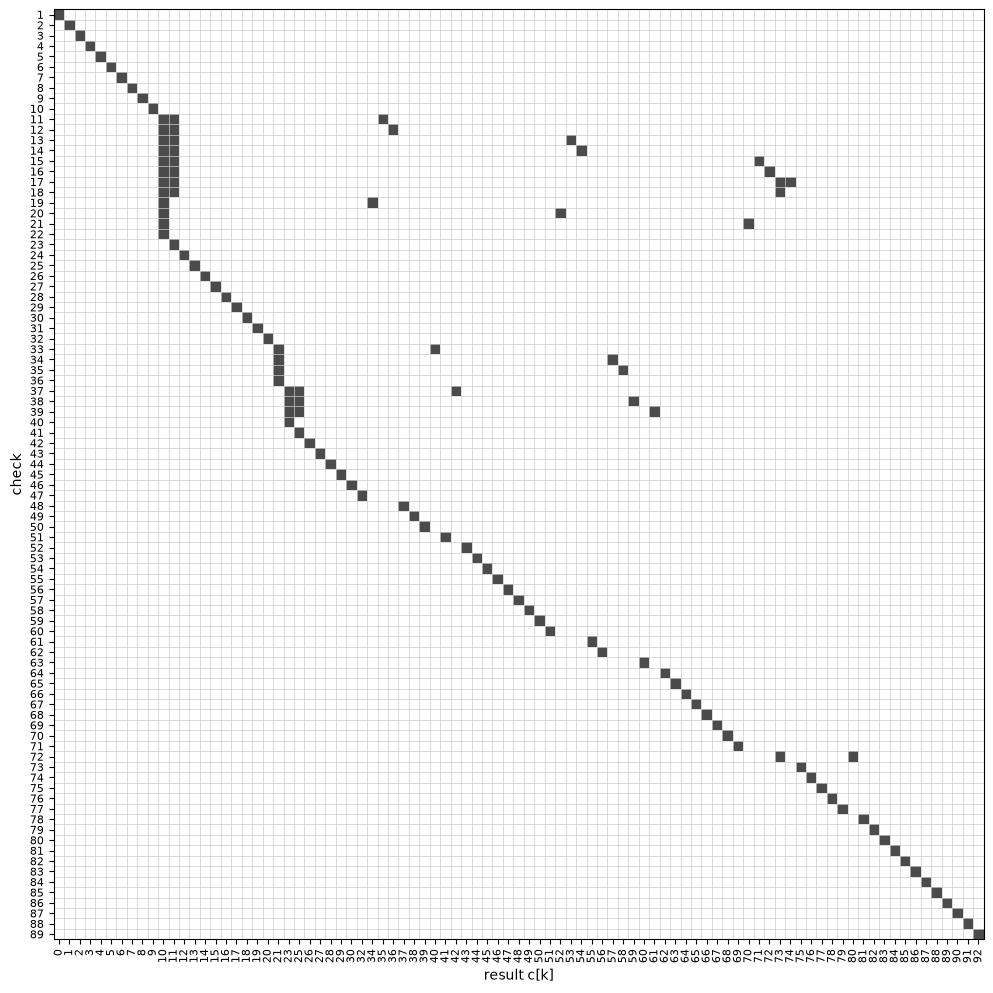

In [5]:
t0 = time.perf_counter()
print(check_detectors(real, circ.detectors))
print("check_detectors: about {:.1f} s".format(time.perf_counter() - t0))
on_results = [d for d in clean.detectors if all(v.name.startswith('c[') for v in d.free_vars())]
others = [str(d) for d in clean.detectors if d not in on_results]
print(len(on_results), "checks on results; {} other facts: {}".format(len(others), ', '.join(others)))
for i, d in enumerate(on_results):
    print("  check {:2d}: {} = 0".format(i + 1, d))
print("how many results a check reads -> how many checks:",
      dict(sorted(Counter(len(list(d.free_vars())) for d in on_results).items())))
fig = draw_checks(on_results, figsize=(12, 14))
fig.savefig(FIG + '/d5_checks.png', bbox_inches='tight')
display(fig)

**What you see.** All 89 DETECTOR lines of the file hold (value 0). The reduction finds 89 checks on the results, and they are sums of the file's lines: the same checks. This took about 1.4 s.

There are 28 more facts, such as `s1_r0` and `s2_r0`. They are values that resets throw away (Section 1). Nobody reads them, so they are not checks.

| results a check reads | checks |
|---|---|
| 1 | 71 |
| 2 | 7 |
| 3 | 10 |
| 4 | 1 |

* Check 1 is `c[82]` = 0.
* Check 33 is `c[42] + c[25] + c[23]` = 0.
* Check 89 reads 4 results: `c[10] + c[11] + c[73] + c[74]` = 0.
* Check 23 is `c[21]` = 0. Stage 3 feeds `c[21]` forward (Section 1); without faults it is always 0.

The picture sorts its rows in its own way (by the first result they read). So its row numbers are not the numbers of the list above.

**What we do.** We draw the reduced diagram on the code's own layout, in 3D, in the style of `Cultivation.ipynb`.

1. `layout_checks` finds the *faces* of the code: nine X checks, drawn as the faces of a triangle.
2. `in_face_variables` writes the diagram in the code's variables: one green spider per face (S1 to S9) and one for the logical X (L). It also adds up the gadgets in these variables.
3. `code_layout(..., regular=False)` puts every spider in its place. The qubits stay at the coordinates of the Stim file, as in `Cultivation.ipynb`.
4. `draw_graph_3d` draws it on three planes. We turn the view (`view=(18, 35)`) so that it is seen from the same side as the d = 5 picture of `Cultivation.ipynb`. `draw_slice` draws the plane at height 2 flat.

We print the phases of the green spiders twice. First without using the checks (`modulo=False`). Then as drawn: by default, `in_face_variables` writes each phase *modulo the checks* (a result that a check fixes is replaced).

We also print the *scalar* of the drawn diagram: a number in front of it, which is not drawn.

The pictures show one run: we set every variable left in the drawn phases to 0 (`substitute_variables`), for the picture only. This is the run where every result is 0. No fault variable is in this diagram: there are no faults yet.

the 9 faces (X checks) of the code, on qubits [0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40]
   (0, 3, 7, 11) XXXIXIIIIIIIIIIIIII
   (17, 25, 32, 36) IIIIIIIXIIIXIIXIXII
   (3, 7, 9, 13) IXXXIXIIIIIIIIIIIII
   (15, 21, 23, 29) IIIIIIXIIXXIIXIIIII
   (21, 27, 29, 34) IIIIIIIIIXIIXXIXIII
   (32, 36, 38, 40) IIIIIIIIIIIIIIXIXXX
   (7, 11, 13, 17, 19, 25) IIXIXXIXXIIXIIIIIII
   (9, 13, 15, 19, 21, 27) IIIXIXXIXXIIXIIIIII
   (19, 25, 27, 32, 34, 38) IIIIIIIIXIIXXIXXIXI
qubits per face -> how many faces: {4: 6, 6: 3}
the logical X of the code is on the 5 qubits [0, 3, 9, 15, 23]
the coordinates of the 19 qubits in the Stim file: {0: (0.0, 0.0), 3: (1.0, 1.0), 7: (2.0, 1.0), 9: (2.0, 3.0), 11: (3.0, 0.0), 13: (3.0, 2.0), 15: (3.0, 4.0), 17: (4.0, 0.0), 19: (4.0, 2.0), 21: (4.0, 4.0), 23: (4.0, 6.0), 25: (5.0, 1.0), 27: (5.0, 3.0), 29: (5.0, 5.0), 32: (6.0, 1.0), 34: (6.0, 3.0), 36: (7.0, 0.0), 38: (7.0, 2.0), 40: (8.0, 0.0)}
green spiders, checks not used (modulo=Fal

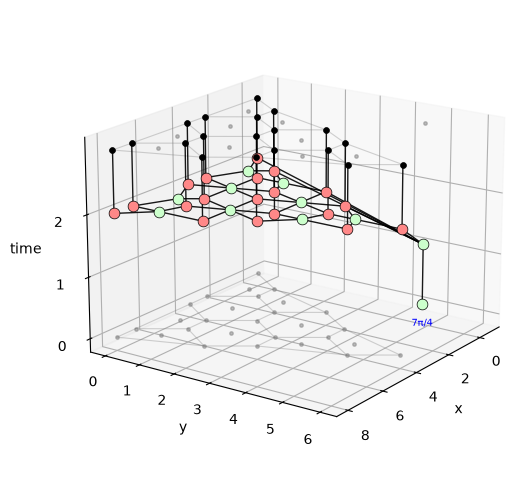

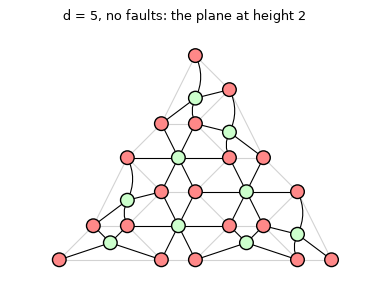

In [6]:
code = colour_code.data()
faces = code.layout_checks(circ.coords)['X']
print("the 9 faces (X checks) of the code, on qubits", list(code.qubits))
for f in faces:
    print("  ", f, ''.join('X' if q in f else 'I' for q in code.qubits))
print("qubits per face -> how many faces:", dict(Counter(len(f) for f in faces)))
side = [q for q, b in zip(code.qubits, code.logical_x[0].x) if b]
print("the logical X of the code is on the {} qubits {}".format(len(side), side))
print("the coordinates of the 19 qubits in the Stim file:", {q: tuple(circ.coords[q]) for q in code.qubits})
plain_lay = code_layout(in_face_variables(clean, code, faces, modulo=False), code.qubits, circ.coords, faces)
print("green spiders, checks not used (modulo=False):")
for name, v in sorted((name, v) for v, name in plain_lay.names.items()):
    print("   {:3s} {}".format(name, plain_lay.graph.phase(v)))
m = in_face_variables(clean, code, faces)
print("gadgets left after in_face_variables (gadgets added up in the faces' variables):", len(phase_polynomial(m)[1]))
lay = code_layout(m, code.qubits, circ.coords, faces, regular=False)       # the qubits at the file's coordinates
print("green spiders, written modulo the checks (the default), as drawn:")
for name, v in sorted((name, v) for v, name in lay.names.items()):
    print("   {:3s} {}".format(name, lay.graph.phase(v)))
for i, f in enumerate(lay.faces):
    print("  face {} {} carries {}".format(i + 1, f, [lay.names[v] for v in lay.face_spiders[i]]))
for logical, state in lay.split:
    print("split off", lay.names[logical], ": a one-legged green spider with phase", lay.graph.phase(state), "pi")
    print("  {} is at height {:.0f}, wired to qubits {}; the state is under it, at height {:.0f}".format(
        lay.names[logical], lay.positions[logical][2],
        sorted(lay.qubits[lay.qubit_spiders[w]] for w in lay.graph.neighbors(logical) if w in lay.qubit_spiders),
        lay.positions[state][2]))
print("heights: the qubits and faces at", sorted({lay.positions[v][2] for v, r in lay.roles.items() if r in ('qubit', 'face')}),
      "; the outputs at", sorted({lay.positions[v][2] for v, r in lay.roles.items() if r == 'output'}))
print("variables left in the phases of the drawn diagram:", len(boolean_variables(lay.graph)))
print("its scalar (a number in front of the diagram, not drawn) is exp(i pi times this sum):")
print(textwrap.fill(str(lay.graph.scalar.phase), width=118, initial_indent='    ', subsequent_indent='    '))
print("    a sum of {} products; it reads {} results".format(len(lay.graph.scalar.phase.terms),
                                                         len(lay.graph.scalar.free_vars())))
run0 = lay.graph.substitute_variables({v: 0 for v in boolean_variables(lay.graph)})   # the run where every result is 0
fig = draw_graph_3d(run0, lay.topology, positions=lay.positions, view=(18, 35))       # the view of Cultivation.ipynb's d = 5 picture
fig.savefig(FIG + '/d5_clean_3d.png', bbox_inches='tight')
display(fig)
fig2 = draw_slice(run0, lay.topology, z=2, positions=lay.positions, title='d = 5, no faults: the plane at height 2',
                  figsize=(4.5, 4))
fig2.savefig(FIG + '/d5_clean_plane.png', bbox_inches='tight')
display(fig2)

**What you see.** The code has 9 faces: 6 with 4 qubits and 3 with 6 qubits. L, the logical X, is on the 5 qubits 0, 3, 9, 15, 23. Their coordinates in the file are (0, 0), (1, 1), (2, 3), (3, 4) and (4, 6). They run along one side of the triangle, from the corner (0, 0) to the corner (4, 6). The third corner is (8, 0).

**The phases.**

* Without the checks (`modulo=False`), the face spiders read results. For example S4 reads `c[75]`, and S1 reads `c[11] + c[78] + c[10] + c[79]`.
* As drawn, every phase is 0. This holds **modulo the checks**: the checks of Section 2 fix each of these results to 0, for example check 18 (`c[11]` = 0) and check 71 (`c[78]` = 0). So the picture holds in every run that passes the checks.
* In the code's variables, **no gadget is left**: the 25 gadgets add up to one phase, 7π/4, on L. It is split off as a one-legged green spider: the state $T^\dagger\vert+\rangle$.
* No spider's phase has a variable left (0). The scalar, a number in front of the diagram that is not drawn, still reads 14 results, in 14 products such as `c[22]⋅c[31]`. So setting the results to 0 for the picture changes nothing that is drawn.

**The 3D picture** (as in `Cultivation.ipynb`, seen from the same side):

* height 2, the plane of the code: the 19 red X-spiders (the qubits, at the coordinates of the Stim file) and the 9 green face spiders S1 to S9, each wired to the qubits of its face;
* height 3: the outputs (black dots);
* height 1, on the right: L, outside the triangle, wired to the 5 qubits 0, 3, 9, 15, 23;
* height 0: the one-legged green spider with 7π/4, under L.

The grey lines at the bottom and the top show the faces.

**The flat picture** is the plane at height 2: the triangle of 19 qubits, with one green spider in each of the 9 faces. Here a corner points up; in `Cultivation.ipynb` the same triangle points to the right.

In every run that passes the checks, this is $T^\dagger\vert+\rangle$ in the d = 5 colour code.

**What we do.** Is the picture still the circuit? There are too many runs to compare them all here, and each one takes long. So we compare them in **one run**: the run where every result, and every value that a reset throws away, is 0.

* A tensor can only be computed when no variable is left, also not in the scalar. So we set every variable of the whole circuit to 0, in both diagrams.
* First we check that the checks allow this run, and that its map is not zero.
* Then `same_map` contracts both to a matrix and compares them.

"The same map" means: equal up to a number that is not zero.

In [7]:
variables = sorted(set(boolean_variables(whole)) | {str(v) for c in clean.constraints for v in c.free_vars()})
zero = {n: 0 for n in variables}
print("{} variables in the whole circuit: {} results and {} values that resets throw away".format(
    len(variables), sum(1 for v in variables if v.startswith('c[')), sum(1 for v in variables if not v.startswith('c['))))
print("the run where all of them are 0 is allowed by the checks:", all(evaluate_phase(c, zero) == 0 for c in clean.constraints))
drawn0 = lay.graph.substitute_variables(zero)
print("in this run the drawn diagram is not the zero map:", bool(abs(drawn0.to_tensor()).max() > 1e-9))
t0 = time.perf_counter()
print("in this run the whole circuit is the same map as the drawn diagram:",
      same_map(whole.substitute_variables(zero), drawn0), "(about {:.0f} s)".format(time.perf_counter() - t0))

127 variables in the whole circuit: 93 results and 34 values that resets throw away
the run where all of them are 0 is allowed by the checks: True
in this run the drawn diagram is not the zero map: True


in this run the whole circuit is the same map as the drawn diagram: True (about 45 s)


**What you see.** The whole circuit has 127 variables: 93 results and 34 values that resets throw away. The checks allow the run where all of them are 0 (True). In this run the drawn diagram is not the zero map (True).

Why all 127, when no spider of the drawn diagram has a variable? The whole circuit has all of them, and the drawn diagram's scalar reads 14 results (cell above). A tensor needs a value for each.

In this run the whole circuit is the same map as the drawn diagram, up to a number (True; about 45 s). This checks **one run** only. `Cultivation.ipynb` compares more runs of this circuit.

## 3. Every fault as a switch

**What we do.** Now the faults. A *fault* here is a Pauli error (X, Y or Z) right after one gate.

* After every gate (not after a measurement), on each qubit of the gate, there is a *place*.
* Place `k` gets two *switches*, `x_k` and `z_k`. Each is 0 or 1. The error at place `k` is $X^{x_k} Z^{z_k}$. So every Pauli fault after every gate (an X and a Z switch per qubit of each gate) is one value of the switches.
* `error_formulas` pushes every switch to the end of the circuit, with the rules that move a Pauli past a gate.
* An X that reaches a T gate turns it into $T^\dagger$ (and a $T^\dagger$ into T). So each T gate gets a *T switch* `f_i`. It is not a new error. It is the sum of the switches that reach that gate as an X.

We print the sizes and the time, and the T switches.

In [8]:
t0 = time.perf_counter()
ef = error_formulas(real)
print("error_formulas: about {:.1f} s".format(time.perf_counter() - t0))
print(len(ef.places), "places;", 2 * len(ef.places), "switches (x_k and z_k);", len(ef.t_flips), "T switches (f_i);",
      len(ef.flips), "results;", len(ef.frame), "output qubits", sorted(ef.frame))
print()
print("the T switches:")
for t in ef.t_flips:
    print("  {:3s} the {:5s} on qubit {:2d} (stage {}); {:3d} switches reach it as an X".format(
        t.name, 'T-dag' if t.adjoint else 'T', t.qubit, t.stage, len(t.switches)))

error_formulas: about 5.8 s
1272 places; 2544 switches (x_k and z_k); 53 T switches (f_i); 93 results; 19 output qubits [0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40]

the T switches:
  f0  the T-dag on qubit  3 (stage 0);  24 switches reach it as an X
  f1  the T-dag on qubit  0 (stage 1);  26 switches reach it as an X
  f2  the T-dag on qubit  3 (stage 1);  22 switches reach it as an X
  f3  the T-dag on qubit  7 (stage 1);  25 switches reach it as an X
  f4  the T-dag on qubit  9 (stage 1);  29 switches reach it as an X
  f5  the T-dag on qubit 11 (stage 1);  17 switches reach it as an X
  f6  the T-dag on qubit 13 (stage 1);  16 switches reach it as an X
  f7  the T-dag on qubit 17 (stage 1);  24 switches reach it as an X
  f8  the T     on qubit  0 (stage 2);  56 switches reach it as an X
  f9  the T     on qubit  3 (stage 2);  55 switches reach it as an X
  f10 the T     on qubit  7 (stage 2);   9 switches reach it as an X
  f11 the T     on qubit  9 (st

**What you see.** One call, about 5.8 s:

| what | how many |
|---|---|
| places | 1272 |
| switches (`x_k` and `z_k`) | 2544 |
| T switches `f_i` (sums of switches, not new ones) | 53 |
| results | 93 |
| output qubits | 19 (the qubits of the [[19,1,5]] code) |

* `f0` is the $T^\dagger$ of the injection (qubit 3, stage 0).
* `f1` to `f7` are the 7 $T^\dagger$ gates of stage 1; `f8` to `f14` the 7 T gates of stage 2.
* `f15` to `f33` are the 19 T gates of stage 6; `f34` to `f52` the 19 of stage 7.
* Between 7 (`f20`) and 301 (`f43`) switches reach a T gate as an X.

**What we do.** A legend: after which gate is each place `k`? `ef.places` lists them. Each entry reads `k:gate(qubit)`.

In [9]:
print("k:gate(qubit) = place k is right after this gate, on this qubit")
for s in range(real.num_stages):
    at = [pl for pl in ef.places if pl.stage == s]
    print("stage {} ({}): places {} to {}".format(s, real.stage(s).name, at[0].index, at[-1].index))
    print(textwrap.fill('  '.join('{}:{}({})'.format(pl.index, pl.name, pl.qubit) for pl in at), width=118,
                        initial_indent='    ', subsequent_indent='    '))

k:gate(qubit) = place k is right after this gate, on this qubit
stage 0 (inject): places 0 to 150
    0:Reset(7)  1:HAD(7)  2:Reset(11)  3:HAD(11)  4:Reset(13)  5:HAD(13)  6:Reset(3)  7:HAD(3)  8:Reset(2)  9:HAD(2)
    10:Reset(4)  11:HAD(4)  12:Reset(18)  13:HAD(18)  14:Reset(0)  15:HAD(0)  16:Reset(5)  17:HAD(5)  18:Reset(17)
    19:HAD(17)  20:Reset(12)  21:Reset(8)  22:Reset(6)  23:CNOT(7)  24:CNOT(12)  25:CNOT(11)  26:CNOT(6)  27:CNOT(13)
    28:CNOT(8)  29:CNOT(7)  30:CNOT(8)  31:CNOT(11)  32:CNOT(12)  33:CNOT(7)  34:CNOT(6)  35:CNOT(13)  36:CNOT(12)
    37:CNOT(2)  38:CNOT(6)  39:CNOT(4)  40:CNOT(8)  41:CNOT(18)  42:CNOT(12)  43:CNOT(6)  44:CNOT(2)  45:CNOT(8)
    46:CNOT(4)  47:CNOT(12)  48:CNOT(18)  49:CNOT(3)  50:CNOT(4)  51:CNOT(17)  52:CNOT(18)  53:CNOT(3)  54:CNOT(2)
    55:CNOT(18)  56:CNOT(17)  57:CNOT(4)  58:CNOT(3)  59:CNOT(2)  60:CNOT(3)  61:T(3)  62:CNOT(2)  63:CNOT(3)
    64:CNOT(4)  65:CNOT(3)  66:CNOT(0)  67:CNOT(2)  68:CNOT(5)  69:CNOT(4)  70:CNOT(2)  71:CNOT(0) 

**What you see.**

| stage | places |
|---|---|
| 0 inject | 0 to 150 |
| 1 double-check d=3, $T^\dagger$ half | 151 to 194 |
| 2 double-check d=3, T half | 195 to 288 |
| 3 grow to d=5, checks | 289 to 545 |
| 4 checks | 546 to 785 |
| 5 checks | 786 to 1025 |
| 6 double-check d=5, first half | 1026 to 1157 |
| 7 double-check d=5, second half | 1158 to 1271 |

A CNOT has two places, one on each of its qubits. A Reset, HAD, T gate or fed-forward Pauli has one. The example pair of Section 5 uses place 304 (`HAD(4)`, stage 3) and place 1242 (`T(9)`, stage 7).

## 4. The reduced diagram, with every variable kept

**What we do.** `error_formulas` pushed every switch to the end (Section 3). What is left is the circuit with these variables in it:

* the 53 T switches `f_i`;
* the X and Z part of the Pauli left on each output qubit, `ox q` and `oz q`;
* the results `c[j]`.

It reduced this circuit **once**: `ef.reduced`. The 2544 switches are not in it. They are only in the formulas (Section 5).

We keep every variable: none is set to a value.

* We write the diagram in the faces' variables (`in_face_variables` with `simplify=False, modulo=False`: only the variables change).
* We name its green spiders with `code_layout`: L, S1 to S9, and h1, h2, ... for the green spiders that are wired to no output.
* We count what is in it.
* We draw it flat, in the style of the error-formulas paper (`layout_gpf` and `draw_graph`): green spiders on the left, red spiders in the middle, leaves on the right.

spiders: the circuit 1554; reduced with f, ox, oz kept 148; reduced without faults 79
T gadgets: 53; angles {'7/4': 27, '5/4': 26}
variables in the drawn diagram: 53 f, 19 ox, 19 oz, 22 results, 0 other []
its parts: {'output': 19, 'qubit': 19, 'logical': 1, 'face': 9, 'hub': 53, 'leaf': 53, 'hidden': 13}


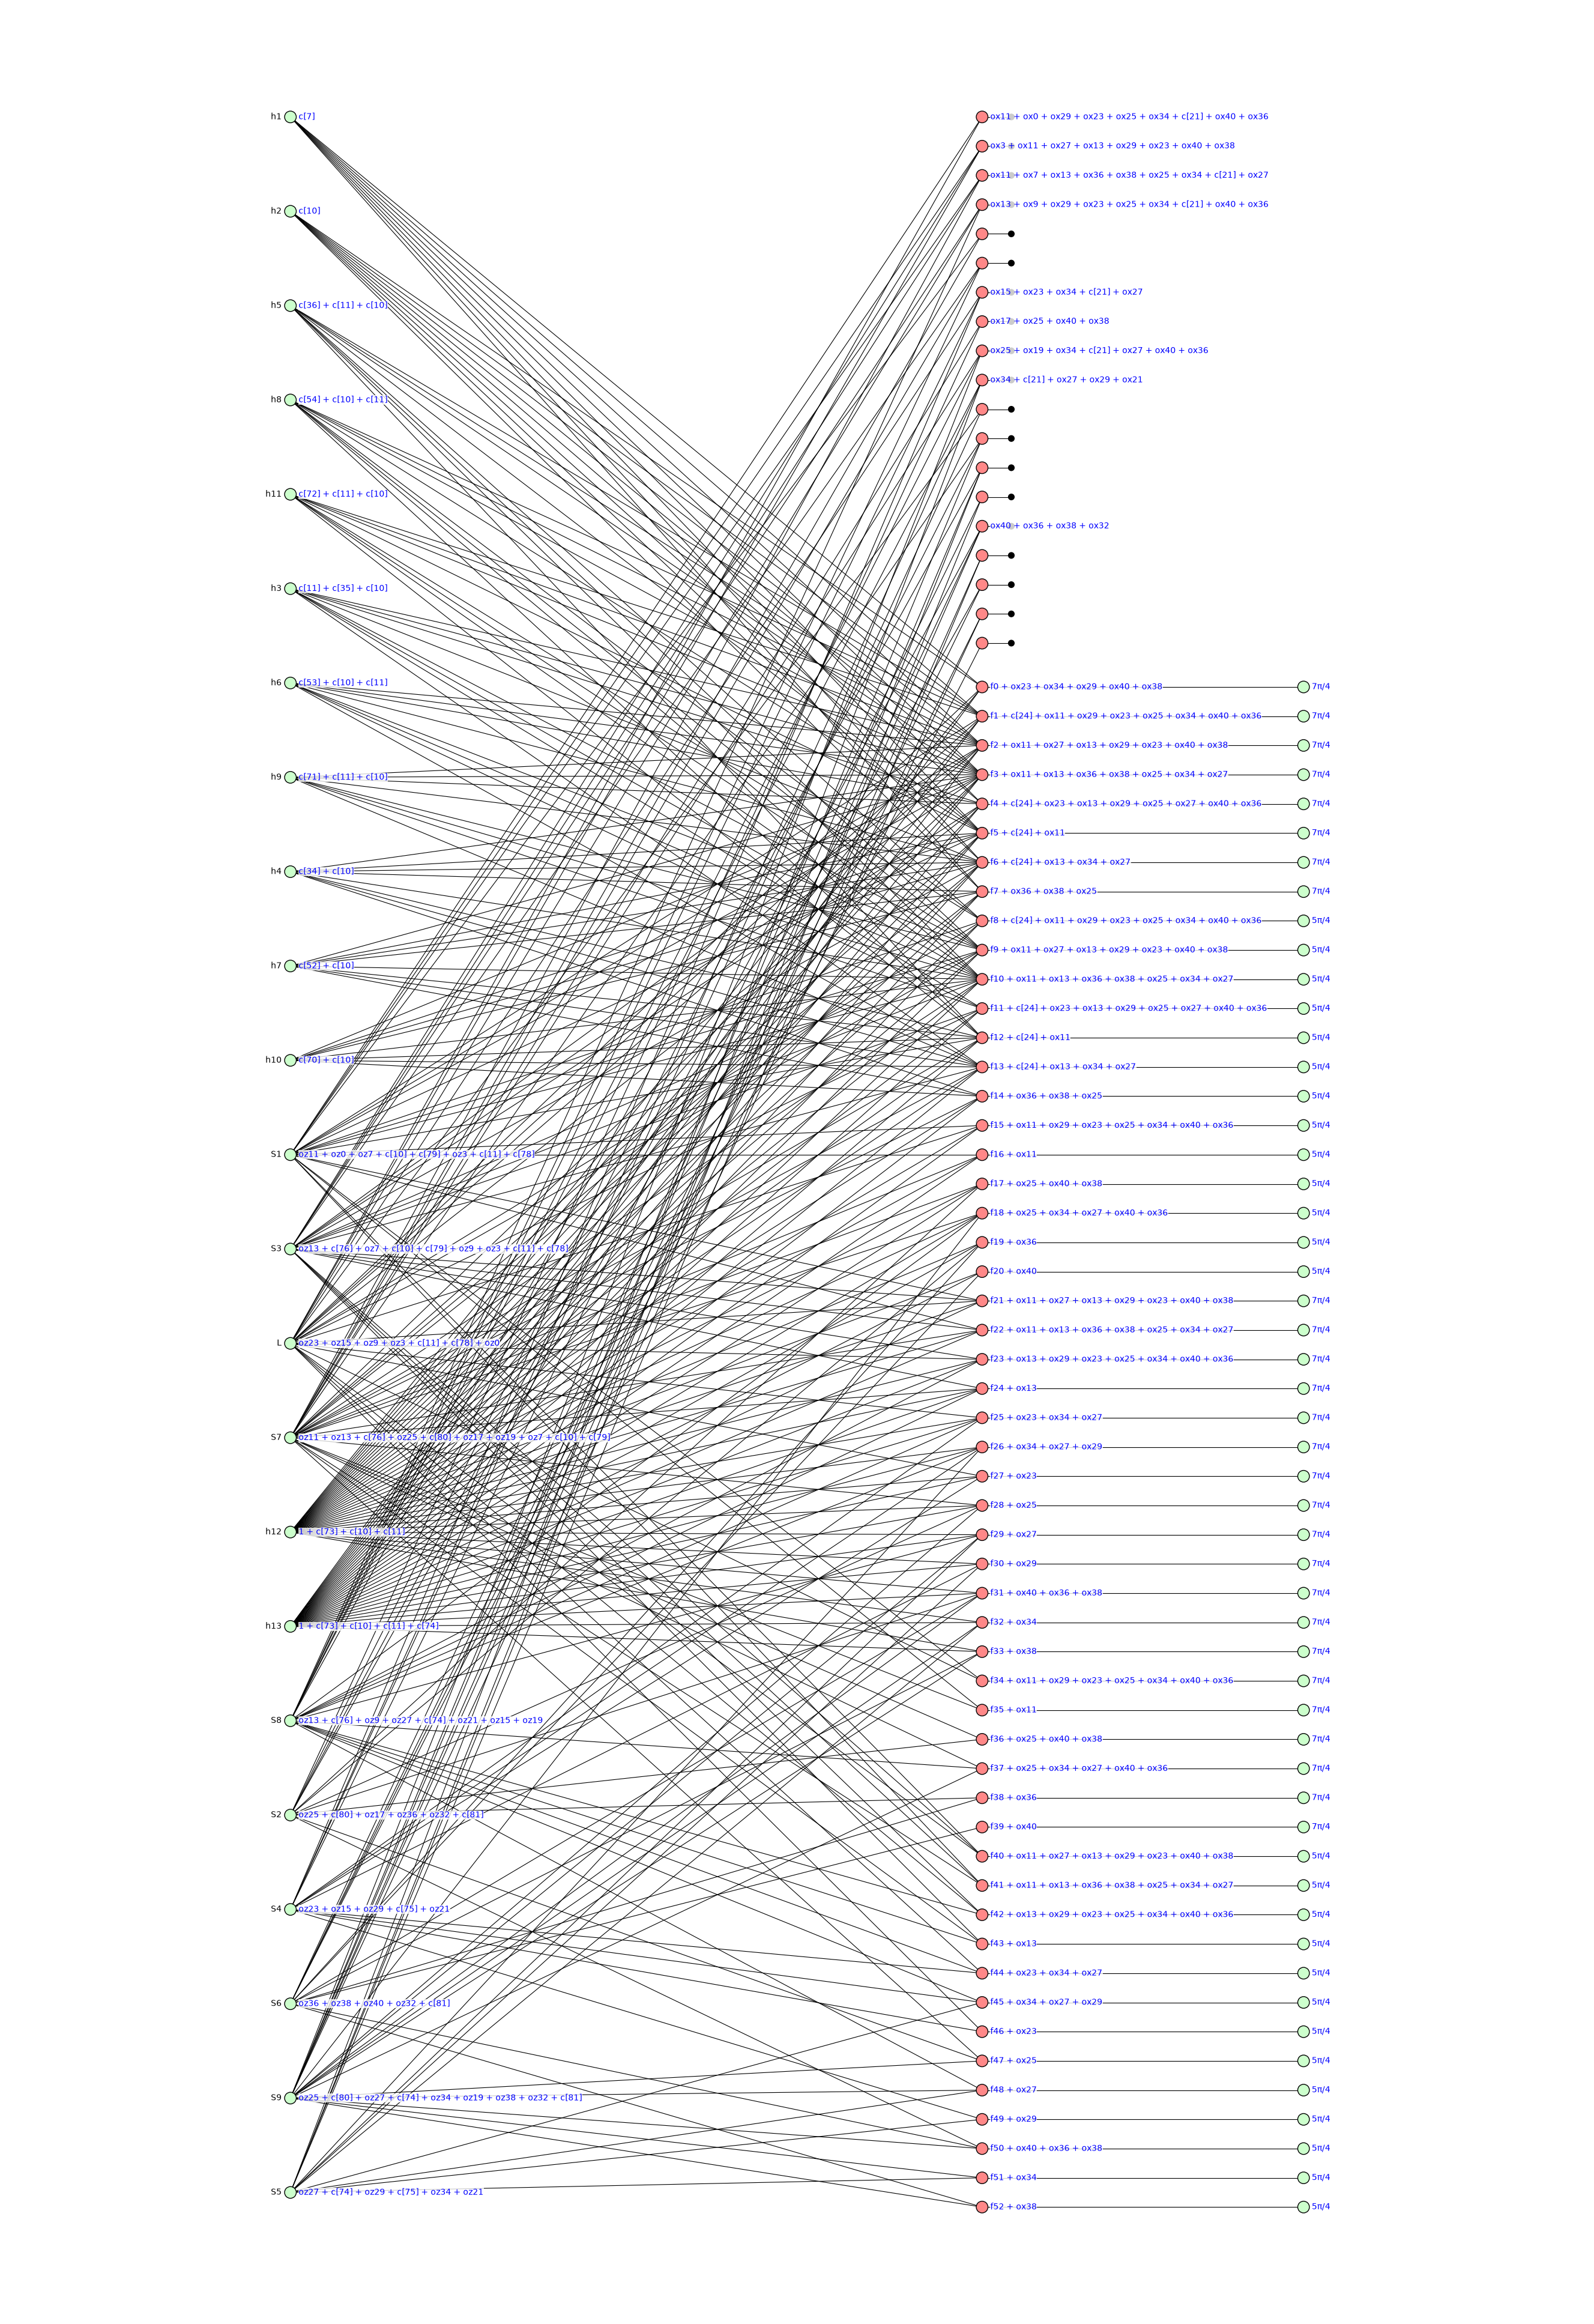

the drawing: about 1.6 s


In [10]:
reduced = ef.reduced.to_graph()
every = in_face_variables(ef.reduced, code, faces, simplify=False, modulo=False)    # only the variables change
lay_every = code_layout(every, code.qubits, circ.coords, faces, regular=False)
G = lay_every.graph
kinds = Counter('f' if v[0] == 'f' else v[:2] if v[:2] in ('ox', 'oz') else 'c' if v.startswith('c[') else 'other'
                for v in boolean_variables(G))
print("spiders: the circuit {}; reduced with f, ox, oz kept {}; reduced without faults {}".format(
    sum(1 for v in whole.vertices() if whole.type(v) != 0), sum(1 for v in reduced.vertices() if reduced.type(v) != 0),
    sum(1 for v in clean.graph.vertices() if clean.graph.type(v) != 0)))
print("T gadgets: {}; angles {}".format(len(phase_polynomial(G)[1]),
                                        dict(Counter(str(G.phase(ls[0])) for _h, ls in phase_polynomial(G)[1]))))
print("variables in the drawn diagram: {} f, {} ox, {} oz, {} results, {} other {}".format(
    kinds['f'], kinds['ox'], kinds['oz'], kinds['c'], kinds['other'],
    sorted(v for v in boolean_variables(G) if not (v[0] == 'f' or v[:2] in ('ox', 'oz') or v.startswith('c[')))))
print("its parts:", dict(Counter(lay_every.roles.values())))
t0 = time.perf_counter()
flat = G.clone()
layout_gpf(flat, leaf_gap=11)
fig = draw_graph(flat, time_axis=False, show_time=False, label_size=10, label_side='right', figsize=(34, 50),
                 names=lay_every.names)
fig.savefig(FIG + '/d5_every_variable_2d.png', bbox_inches='tight')
display(fig)
print("the drawing: about {:.1f} s".format(time.perf_counter() - t0))

**What you see.**

| diagram | spiders |
|---|---|
| the circuit | 1554 |
| reduced, with `f`, `ox`, `oz` kept | 148 |
| reduced, no faults (Section 2) | 79 |

With faults, the 53 T gadgets stay **53 gadgets**, one per T gate: 27 with angle 7π/4 (the $T^\dagger$ gates) and 26 with angle 5π/4 (the T gates). The drawn diagram has all 53 `f`, 19 `ox`, 19 `oz` and 22 results in it. Nothing was set to a value. (The other results are only in the checks.)

Its parts: the green spiders (1 logical L, 9 faces, 13 hidden ones), 19 red output spiders with their 19 outputs, 53 hubs, 53 leaves.

The picture (drawn in about 1.6 s):

* On the left, the green spiders L, S1 to S9 and h1 to h13, with their names.
* In the middle, the red spiders. The top 19 are the output qubits, each wired to its output (a black dot) on its right. For the 9 output spiders with a phase (next cell), the phase is written over the dot; for the others the dot shows. The 53 red spiders below them are the gadget hubs.
* On the right, the 53 leaves with their angles.
* The phases are written next to the spiders.

The picture shows the shape. It is too dense to read every phase: the next cell prints them all.

Why 5π/4 and not π/4? 5π/4 = π/4 + π. We do not move the extra π away: the step that does it (`normalize_gadget_angles`) drops a sign that depends on the variables.

**What we do.** The picture is too dense to read every phase. So we print every phase:

* each green spider (L, the faces S1 to S9, the hidden ones h1 to h13);
* each output spider that has a phase. For it we also ask the code (`code.contains`): is Z on the qubits of its `ox` a stabilizer of the code?
* each gadget hub, with the T switch `f_i` it reads, its T gate, and the angle of its leaf.

In [11]:
order = {'logical': 0, 'face': 1, 'hidden': 2}
print("green spiders (name: number of wires | phase):")
for _o, _i, name, v in sorted((order[lay_every.roles[v]], int(name[1:] or 0), name, v)
                              for v, name in lay_every.names.items()):
    print("  {:3s} {:2d} wires | {}".format(name, G.vertex_degree(v), G.phase(v)))
print()
print("output spiders with a phase:")
for j, v in sorted((j, v) for v, j in lay_every.qubit_spiders.items()):
    if G.phase(v) != 0:
        qs = sorted(int(x.name[2:]) for x in G.phase(v).free_vars() if x.name[:2] == 'ox')
        z = ''.join('Z' if q in qs else 'I' for q in code.qubits)
        print("  qubit {:2d}: {}".format(code.qubits[j], G.phase(v)))
        print("      ox on qubits {}; Z on them is a stabilizer of the code: {}".format(qs, code.contains(z)))
print("output spiders with phase 0:", sorted(code.qubits[j] for v, j in lay_every.qubit_spiders.items() if G.phase(v) == 0))
with_phase = [v for v in lay_every.qubit_spiders if G.phase(v) != 0]
ox_counts = [sum(1 for x in G.phase(v).free_vars() if x.name[:2] == 'ox') for v in with_phase]
print("output spiders with a phase: {}; each reads ox of {} to {} qubits; {} of them also read c[21]".format(
    len(with_phase), min(ox_counts), max(ox_counts),
    sum(1 for v in with_phase if 'c[21]' in {x.name for x in G.phase(v).free_vars()})))
print()
t_of = {t.name: t for t in ef.t_flips}
hubs = []
for v, role in lay_every.roles.items():
    if role == 'hub':
        f = next(x.name for x in G.phase(v).free_vars() if x.name[0] == 'f')
        leaf = next(w for w in G.neighbors(v) if lay_every.roles.get(w) == 'leaf')
        hubs.append((int(f[1:]), f, v, leaf))
print("gadget hubs, one per T gate (T switch | which T gate | hub phase | leaf angle):")
for _i, f, v, leaf in sorted(hubs):
    t = t_of[f]
    print("  {:3s} | {:5s} on qubit {:2d}, stage {} | {} | {}".format(
        f, 'T-dag' if t.adjoint else 'T', t.qubit, t.stage, G.phase(v), G.phase(leaf)))
print("results in the hubs:", sorted({x.name for _i, f, v, leaf in hubs for x in G.phase(v).free_vars()
                                       if x.name.startswith('c[')}))
print("hubs that read c[24]:", sum(1 for _i, f, v, leaf in hubs if 'c[24]' in {x.name for x in G.phase(v).free_vars()}))

green spiders (name: number of wires | phase):
  L   22 wires | oz23 + oz15 + oz9 + oz3 + c[11] + c[78] + oz0
  S1  20 wires | oz11 + oz0 + oz7 + c[10] + c[79] + oz3 + c[11] + c[78]
  S2  12 wires | oz25 + c[80] + oz17 + oz36 + oz32 + c[81]
  S3  20 wires | oz13 + c[76] + oz7 + c[10] + c[79] + oz9 + oz3 + c[11] + c[78]
  S4  12 wires | oz23 + oz15 + oz29 + c[75] + oz21
  S5  12 wires | oz27 + c[74] + oz29 + c[75] + oz34 + oz21
  S6  12 wires | oz36 + oz38 + oz40 + oz32 + c[81]
  S7  26 wires | oz11 + oz13 + c[76] + oz25 + c[80] + oz17 + oz19 + oz7 + c[10] + c[79]
  S8  18 wires | oz13 + c[76] + oz9 + oz27 + c[74] + oz21 + oz15 + oz19
  S9  18 wires | oz25 + c[80] + oz27 + c[74] + oz34 + oz19 + oz38 + oz32 + c[81]
  h1   8 wires | c[7]
  h2   8 wires | c[10]
  h3   8 wires | c[11] + c[35] + c[10]
  h4   8 wires | c[34] + c[10]
  h5   8 wires | c[36] + c[11] + c[10]
  h6   8 wires | c[53] + c[10] + c[11]
  h7   8 wires | c[52] + c[10]
  h8   8 wires | c[54] + c[10] + c[11]
  h9   8 wires

**What you see.** (The output prints the terms of a sum in another order.)

| part | reads |
|---|---|
| L | `oz` of its 5 qubits 0, 3, 9, 15, 23, plus `c[11] + c[78]` |
| S1 to S9 | `oz` of exactly the qubits of its face, plus results |
| h1 to h13 | results only (h12 and h13 also a constant 1) |
| output spider (9 of the 19) | `ox` of 4 to 8 qubits; 6 of them also `c[21]` |
| gadget hub | its own `f_i`, plus `ox` of some qubits; 8 hubs also `c[24]` |
| leaf | 7π/4 for a $T^\dagger$ gate, 5π/4 for a T gate |

* A hub reads `f_i`. When it is 1, that T gate turns around: T becomes $T^\dagger$, and $T^\dagger$ becomes T. An `ox` in a hub does the same to that gadget.
* An output spider reads the X errors on some qubits. Z on these qubits is a stabilizer of the code (`code.contains`: True for all 9). So the sum is 1 exactly when the X errors make this Z stabilizer fire.
* `c[21]` and `c[24]` are results that stage 3 feeds forward (Section 1).
* h12 and h13 have 34 wires each; they are the two dense fans in the picture. h1 to h11 have 8 wires each.

**What we do.** A tensor check would contract the whole diagram for random values of all variables. That takes long here, and random values can give the zero map (a run that cannot happen), which proves little. So here we check the **structure** instead.

* `in_face_variables(..., simplify=False, modulo=False)` should be exactly `change_variables` with the rows of L and of the 9 faces.
* `code_layout` should only give places to the spiders.

So we build `change_variables(ef.reduced, rows)` ourselves and compare it with the drawn diagram, vertex by vertex: kind, phase, wires, outputs. We also compare the drawn diagram with `ef.reduced` itself.

In [12]:
rows = [[int(b) for b in lx.x] for lx in code.logical_x] + [[int(q in f) for q in code.qubits] for f in faces]
direct = change_variables(ef.reduced.graph, rows)
R = ef.reduced.graph
print("change_variables(ef.reduced, the rows of L and of the 9 faces), against the drawn diagram:")
print("  the same vertices:", set(direct.vertices()) == set(G.vertices()), "({} vertices)".format(len(list(G.vertices()))))
print("  each vertex has the same kind and the same phase:",
      all(direct.type(v) == G.type(v) and direct.phase(v) == G.phase(v) for v in G.vertices()))
print("  the same wires, of the same kind:",
      set(direct.edges()) == set(G.edges()) and all(direct.edge_type(e) == G.edge_type(e) for e in G.edges()))
print("  the same outputs, in the same order:", list(direct.outputs()) == list(G.outputs()))
print("ef.reduced itself, against the drawn diagram:")
print("  the same vertices:", set(R.vertices()) == set(G.vertices()))
print("  every spider that is not green (outputs, hubs, leaves) has the same phase:",
      all(R.phase(v) == G.phase(v) for v in G.vertices() if G.type(v) != VertexType.Z or lay_every.roles.get(v) == 'leaf'))

change_variables(ef.reduced, the rows of L and of the 9 faces), against the drawn diagram:
  the same vertices: True (167 vertices)
  each vertex has the same kind and the same phase: True
  the same wires, of the same kind: True
  the same outputs, in the same order: True
ef.reduced itself, against the drawn diagram:
  the same vertices: True
  every spider that is not green (outputs, hubs, leaves) has the same phase: True


**What you see.** Every answer is True.

* The drawn diagram **is** `change_variables(ef.reduced, rows)`: the same 167 vertices, each with the same kind and phase, the same wires, the same outputs. So `in_face_variables` with `simplify=False, modulo=False` only changed the variables, and `code_layout` only gave places.
* Against `ef.reduced` itself: the same vertices, and the outputs, hubs and leaves keep their phases. Only the green spiders got new phases and new wires: the new variables.

`change_variables` only changes the order of the sum; its docstring says the map stays the same. This check is about the structure: it does not contract tensors.

It does not test `ef.reduced` itself against the circuit with faults. The evidence for that is in Section 6: the fast way (which uses `ef.reduced`) and the slow way (which puts the error gates into the circuit) agree on every pattern we tried both ways. The library's tests check it too.

## 5. All the equations

**What we do.** Every formula, in full (`ef.formula`), each on its own line. A formula is a sum of switches. It is 1 when an odd number of its switches are on.

The lines are long: some formulas have hundreds of switches.

In [13]:
print("The {} T switches (f_i is 1 when the sum is odd):".format(len(ef.t_flips)))
for t in ef.t_flips:
    print("  {} = {}".format(t.name, ef.formula(t.name)))
print()
print("The {} results (c[j] flips when the sum is odd):".format(len(ef.flips)))
for c in ('c[{}]'.format(j) for j in range(len(ef.flips))):
    print("  {} = {}".format(c, ef.formula(c)))
print()
print("The Pauli left on the {} output qubits (X part ox, Z part oz):".format(len(ef.frame)))
for q in sorted(ef.frame):
    print("  ox{} = {}".format(q, ef.formula('ox{}'.format(q))))
    print("  oz{} = {}".format(q, ef.formula('oz{}'.format(q))))
print()
print("shortest and longest T switch:", min((len(t.switches), t.name) for t in ef.t_flips),
      max((len(t.switches), t.name) for t in ef.t_flips))
print("results whose formula is empty (no switch reaches them):",
      [c for c in ('c[{}]'.format(j) for j in range(len(ef.flips))) if not ef.flips[c]])

The 53 T switches (f_i is 1 when the sum is odd):
  f0 = z2 + x3 + z4 + x5 + z6 + x7 + x21 + x22 + x26 + x28 + x29 + x30 + x34 + x37 + x38 + x39 + x40 + x44 + x46 + x50 + x53 + x54 + x58 + x60
  f1 = z0 + x1 + z2 + x3 + z6 + x7 + x22 + x23 + x26 + x29 + x34 + x37 + x38 + x44 + x49 + x54 + x59 + x62 + x66 + x67 + x71 + z74 + x75 + x84 + x93 + x126
  f2 = z6 + x7 + x49 + x53 + x57 + x58 + x59 + x60 + x61 + x63 + x65 + z74 + x75 + z78 + x79 + x84 + x86 + x92 + x103 + x111 + x118 + x134
  f3 = z0 + x1 + x23 + x29 + x33 + z74 + x75 + z76 + x77 + z78 + x79 + x80 + x82 + x85 + x87 + x90 + x94 + x96 + x101 + x105 + x106 + x113 + x120 + x128 + x136
  f4 = z0 + x1 + z4 + x5 + z6 + x7 + x21 + x23 + x28 + x30 + x39 + x40 + x46 + x50 + x57 + x64 + x68 + x69 + x73 + z78 + x79 + x82 + x83 + x87 + x89 + x96 + x98 + x107 + x138
  f5 = z2 + x3 + x25 + x31 + z74 + x75 + z76 + x77 + x80 + x85 + x90 + x95 + x100 + x108 + x115 + x122 + x130
  f6 = z4 + x5 + x27 + x35 + z76 + x77 + z78 + x79 + x82 + x87 + x9

**What you see.** Every formula, in full.

* **T switches.** `f20` is the shortest (7 switches), `f43` the longest (301).
* **Results.** Some read only `x` switches, for example `c[0] = x22 + x25 + ...`: an X error flips a measured result. Others also read `z` switches, for example `c[4] = x0 + z1 + ...`: a Hadamard turns a Z error into an X before the measurement. Every result has at least one switch (the list of empty ones is empty).
* **Outputs.** `ox q` and `oz q` are the X and Z part of the Pauli left on output qubit `q`.

**What we do.** Every check, as a sum of switches (`ef.detector_switches`). A check fires when its sum is odd. We also test that these are the checks of Section 2, in the same order, so that the numbers match.

In [14]:
checks = ef.detector_switches()
check_switches = [(d, s) for d, s in checks if all(v.name.startswith('c[') for v in d.free_vars())]
print(len(checks), "facts of the circuit without faults;", len(check_switches), "of them are checks on results.")
print("the same checks, in the same order, as in Section 2:",
      [str(d) for d, s in check_switches] == [str(d) for d in on_results])
for i, (d, s) in enumerate(check_switches):
    print("  check {:2d}: {} fires when {} is odd".format(i + 1, d, ef.formula(s)))
print("switches per check: fewest", min(len(s) for d, s in check_switches), "; most", max(len(s) for d, s in check_switches))

117 facts of the circuit without faults; 89 of them are checks on results.
the same checks, in the same order, as in Section 2: True
  check  1: c[82] fires when x1042 + z1043 + z1117 + z1118 + z1128 + z1193 + z1230 + x1261 is odd
  check  2: c[77] fires when x1036 + z1037 + z1091 + z1092 + z1124 + z1189 + z1204 + x1256 is odd
  check  3: c[17] fires when x251 + x271 + x272 + x282 is odd
  check  4: c[3] fires when x83 + x88 + x89 + x99 is odd
  check  5: c[15] fires when x248 + x277 + x278 + x288 is odd
  check  6: c[14] fires when x247 + x273 + x274 + x284 is odd
  check  7: c[18] fires when x252 + x269 + x270 + x280 is odd
  check  8: c[16] fires when x255 + x275 + x276 + x286 is odd
  check  9: c[2] fires when x21 + x27 + x28 + x29 + x30 + x33 + x35 + x39 + x40 + x46 + x49 + x50 + x53 + x58 + x59 + x60 + x61 + x63 + x64 + x65 + x68 + x69 + x73 + x80 + x83 + x84 + x85 + x89 + x92 + x94 + x96 + x97 + x98 + x100 + x101 + x103 + x105 + x107 + x109 + x110 + x111 + x112 + x113 + x119 + x

**What you see.** 117 facts; 89 of them are checks on results. They are the 89 checks of Section 2, in the same order (True).

* A check is a sum of results, so its switches are the sum of their formulas. A switch that is in two of them cancels.
* The shortest checks have 4 switches, for example check 4: `c[3]` fires when `x83 + x88 + x89 + x99` is odd.
* The longest has 619 switches.

**What we do.** One worked example: a pair of faults.

We pick it with fixed seeds: two different gates at random, then a random fault at each gate. We take the first seed (0, 1, 2, ...) whose pair flips no result but turns a T gate around. Such a pair cannot be decided by adding up the checks alone.

The *signature* of a pattern of faults is the value of every formula. It says which results the pattern flips, which T switches it turns on, and which Pauli it leaves on the outputs.

1. `ef.switches` gives the switches that the pair turns on.
2. For each formula, we look which of these switches it contains.
3. Two of them in one formula cancel: 1 + 1 = 0.
4. We compare with `ef.signature`.

In [15]:
singles = ef.single_faults()
seed, pair = 0, None
while pair is None:                         # the first seed whose pair flips no result and turns a T gate around
    rng = random.Random(seed)
    a, b = rng.sample(range(len(singles)), 2)
    candidate = {**rng.choice(singles[a][1]), **rng.choice(singles[b][1])}
    if not ef.signature(candidate)[0] and ef.signature(candidate)[1]:
        pair = candidate
    else:
        seed += 1
print("seed {}: the example pair {}".format(seed, pair))
print("  ", ef.describe(pair))
on = ef.switches(pair)
print("its switches that are on:", sorted(on))
formulas = ([(c, ef.flips[c]) for c in ('c[{}]'.format(j) for j in range(len(ef.flips)))]
            + [(t.name, t.switches) for t in ef.t_flips]
            + [('{}{}'.format(o, q), ef.frame[q][k]) for q in sorted(ef.frame) for k, o in enumerate(('ox', 'oz'))])
ones = []
for name, switches in formulas:
    hits = sorted(on & switches)
    if hits:
        print("  {:5s} contains {:12s} -> value {}".format(name, ' + '.join(hits), len(hits) % 2))
        if len(hits) % 2:
            ones.append(name)
print("the other {} formulas contain none of its switches -> value 0".format(
    sum(1 for name, switches in formulas if not on & switches)))
print("value 1:", ones)
print("signature(pair):", [sorted(part) for part in ef.signature(pair)], "; the same:",
      set(ones) == set().union(*ef.signature(pair)))

seed 26: the example pair {1242: 'Z', 304: 'X'}
   X on qubit 4 after the HAD (stage 3, gate 15); Z on qubit 9 after the T (stage 7, gate 47)
its switches that are on: ['x304', 'z1242']
  f15   contains x304         -> value 1
  f16   contains x304         -> value 1
  f23   contains x304         -> value 1
  f24   contains x304         -> value 1
  f34   contains x304         -> value 1
  f35   contains x304         -> value 1
  f42   contains x304         -> value 1
  f43   contains x304         -> value 1
  ox0   contains x304         -> value 1
  ox9   contains x304         -> value 1
  oz9   contains z1242        -> value 1
  ox11  contains x304         -> value 1
  ox13  contains x304         -> value 1
the other 171 formulas contain none of its switches -> value 0
value 1: ['f15', 'f16', 'f23', 'f24', 'f34', 'f35', 'f42', 'f43', 'ox0', 'ox9', 'oz9', 'ox11', 'ox13']
signature(pair): [[], ['f15', 'f16', 'f23', 'f24', 'f34', 'f35', 'f42', 'f43'], ['ox0', 'ox11', 'ox13', 'ox9', 'oz9

**What you see.** Seed 26 is the first seed whose pair flips no result but turns a T gate around. The pair is `{1242: 'Z', 304: 'X'}`:

* an X on qubit 4 after the HAD (stage 3, gate 15);
* a Z on qubit 9 after the T (stage 7, gate 47).

It turns on 2 switches: `x304` and `z1242`.

| formula | contains | value |
|---|---|---|
| `f15`, `f16`, `f23`, `f24` (stage 6) | `x304` | 1 |
| `f34`, `f35`, `f42`, `f43` (stage 7) | `x304` | 1 |
| `ox0`, `ox9`, `ox11`, `ox13` | `x304` | 1 |
| `oz9` | `z1242` | 1 |

The other 171 formulas contain none of them: value 0. So the pair flips **no result**, turns 8 T gates around, and leaves X on qubits 0, 11, 13 and Y (X and Z) on qubit 9. This is exactly `signature(pair)` (True).

## 6. The fast way and the slow way

Three words first. `classify` gives each pattern of faults one of them:

| verdict | what it means |
|---|---|
| caught | in every run, a check of the circuit or the final check fires: the run is thrown away |
| harmless | some runs pass; each of them gives the same state as without faults |
| wrong | some run passes and gives a wrong state |

Each verdict includes the *final check*. After the circuit, the code at the end is checked once more, perfectly (all its stabilizers). A run that fails it is thrown away too. Then the states with and without faults are compared (up to a number that is not zero).

**What we do.** The **fast way**, on the example pair:

1. the signature: add up the formulas (no diagram);
2. `classify`: the verdict from the signature.

Inside, `classify` puts the pair's values into the reduced diagram of Section 4 when it needs to, and reduces it again. A pair that turns T gates around needs this once for its set of T gates. We do not draw that diagram. We time each step. We also ask again (the verdict is remembered). Then we ask about each fault alone: its signature and its verdict.

In [16]:
t0 = time.perf_counter()
sig = ef.signature(pair)
t_sig = time.perf_counter() - t0
print("1. signature (add up formulas): {} results flipped, {} T switches on, {} output switches on; about {:.5f} s".format(
    len(sig[0]), len(sig[1]), len(sig[2]), t_sig))
t0 = time.perf_counter()
fast = ef.classify(pair)
t_fast = time.perf_counter() - t0
print("2. classify(pair) = {}: about {:.2f} s".format(fast, t_fast))
t0 = time.perf_counter()
ef.classify(pair)
print("   asked again: the verdict is remembered for this signature, about {:.5f} s".format(time.perf_counter() - t0))
print("each fault alone:")
for k, letter in sorted(pair.items()):
    print("   {}: signature {}; classify = {}".format(ef.describe({k: letter}),
                                                   [sorted(part) for part in ef.signature({k: letter})],
                                                   ef.classify({k: letter})))

1. signature (add up formulas): 0 results flipped, 8 T switches on, 5 output switches on; about 0.00006 s


2. classify(pair) = caught: about 0.38 s
   asked again: the verdict is remembered for this signature, about 0.00003 s
each fault alone:
   X on qubit 4 after the HAD (stage 3, gate 15): signature [[], ['f15', 'f16', 'f23', 'f24', 'f34', 'f35', 'f42', 'f43'], ['ox0', 'ox11', 'ox13', 'ox9']]; classify = harmless


   Z on qubit 9 after the T (stage 7, gate 47): signature [[], [], ['oz9']]; classify = caught


**What you see.**

| step | result | time |
|---|---|---|
| 1. signature | no result flipped; 8 T switches on; 5 output switches on | about 0.00006 s |
| 2. `classify` | **caught** | about 0.38 s |
| asked again | caught (remembered) | about 0.00003 s |

Each fault alone:

| fault | results flipped | T switches on | output switches on | verdict |
|---|---|---|---|---|
| X on qubit 4 (place 304) | none | `f15`, `f16`, `f23`, `f24`, `f34`, `f35`, `f42`, `f43` | `ox0`, `ox9`, `ox11`, `ox13` | harmless |
| Z on qubit 9 (place 1242) | none | none | `oz9` | caught |

* The Z alone flips no result and turns no T gate around. It only leaves a Z on qubit 9 at the end. So the circuit's checks cannot see it. The final check does: caught.
* The X alone is harmless: some of its runs pass every check, and they give the same state as without faults.
* The pair flips no result, so adding up the checks of Section 5 shows nothing. It turns the same 8 T gates around as the X alone. So `classify` needs the diagram with these 8 T switches on, reduced once for this set of T gates.
* The pair differs from the X alone only by `oz9`: a Z on qubit 9 after the last measurement. So the circuit's checks see the same in both, and some runs pass them, as for the X alone. But the pair is caught. So in each of these runs, the final check fires.

**What we do.** The **slow way**, on the same pair.

* `program_with` puts the two error gates into the circuit.
* `classify_directly` reduces the whole circuit with the errors in it, and gives a verdict. We time it.

In [17]:
with_errors = ef.program_with(pair)
big = with_errors.quantum_graph()
print("the errors are in stages", sorted({ef.places[k].stage for k in pair}))
print("the whole circuit: {} spiders; with the two error gates: {} spiders".format(
    sum(1 for v in whole.vertices() if whole.type(v) != 0), sum(1 for v in big.vertices() if big.type(v) != 0)))
t0 = time.perf_counter()
slow = ef.classify_directly(pair)
t_slow = time.perf_counter() - t0
print("classify_directly(pair) = {}: about {:.2f} s".format(slow, t_slow))
print("the same verdict as the fast way:", slow == fast)

the errors are in stages [3, 7]
the whole circuit: 1554 spiders; with the two error gates: 1556 spiders


classify_directly(pair) = caught: about 1.59 s
the same verdict as the fast way: True


**What you see.** The errors are in stages 3 and 7. The whole circuit has 1554 spiders; with the two error gates it has 1556.

`classify_directly` reduces all of it: **caught**, about 1.59 s. The same verdict as the fast way (True).

For this one pair, the fast way took about 0.38 s and the slow way about 1.59 s.

**What we do.** Every single fault, the fast way. `single_faults` lists them per gate:

* 3 kinds after a one-qubit gate: X, Y, Z;
* 15 kinds after a CNOT: any two-qubit Pauli except II.

We count the verdicts per kind of gate, and time it. Then we count how many different signatures the single faults have, and how many different sets of T gates they turn around.

In [18]:
t0 = time.perf_counter()
table = Counter()
for place, kinds_at in singles:
    for f in kinds_at:
        table[place.name, ef.classify(f)] += 1
t_singles = time.perf_counter() - t0
n_single = sum(len(k) for _p, k in singles)
print("{} gates with faults; {} single faults (3 kinds after a 1-qubit gate, 15 after a CNOT)".format(len(singles), n_single))
print("after a            | caught | harmless | wrong")
for gate in sorted({g for g, _v in table}):
    print("  {:16s} | {:6d} | {:8d} | {:5d}".format(gate, table[gate, 'caught'], table[gate, 'harmless'], table[gate, 'wrong']))
print("  all              | {:6d} | {:8d} | {:5d}".format(*(sum(n for (g, v), n in table.items() if v == w)
                                                         for w in ('caught', 'harmless', 'wrong'))))
print("all single faults, the fast way: about {:.0f} s".format(t_singles))
flat_singles = [f for _p, k in singles for f in k]
sigs = {ef.mask(f) for f in flat_singles}
tsets = {ef.signature(f)[1] for f in flat_singles}
print("the {} single faults have {} different signatures".format(len(flat_singles), len(sigs)))
print("{} single faults turn T gates around; they turn around {} different sets of T gates".format(
    sum(1 for f in flat_singles if ef.signature(f)[1]), len([t for t in tsets if t])))

795 gates with faults; 8109 single faults (3 kinds after a 1-qubit gate, 15 after a CNOT)
after a            | caught | harmless | wrong
  CNOT             |   6845 |      310 |     0
  HAD              |    260 |      130 |     0
  ParityControlled |     51 |        0 |     0
  Reset            |    236 |      118 |     0
  T                |    159 |        0 |     0
  all              |   7551 |      558 |     0
all single faults, the fast way: about 87 s
the 8109 single faults have 3472 different signatures


5054 single faults turn T gates around; they turn around 222 different sets of T gates


**What you see.** 795 gates can have a fault: 8109 single faults.

| after a | caught | harmless | wrong |
|---|---|---|---|
| CNOT | 6845 | 310 | 0 |
| HAD | 260 | 130 | 0 |
| fed-forward Pauli (`ParityControlled`) | 51 | 0 | 0 |
| Reset | 236 | 118 | 0 |
| T | 159 | 0 | 0 |
| all | 7551 | 558 | **0** |

**No single fault is wrong.** All 8109 took about 87 s.

Why it is fast. There are two reasons:

1. The 8109 single faults have only 3472 different signatures. `classify` decides each signature at most once, and remembers it.
2. 5054 single faults turn T gates around, but they turn around only 222 different sets of T gates. For each set, `classify` reduces one diagram, once. Its checks can then catch a signature of that set by adding up, with no new diagram.

Only a signature that none of this catches gets a small diagram of its own.

**What we do.** We check the fast way against the slow way on 30 single faults. We draw them at random from the list of all single faults (seed 5), and decide each one both ways.

In [19]:
sample1 = random.Random(5).sample(flat_singles, 30)
t0 = time.perf_counter()
slow1 = [ef.classify_directly(f) for f in sample1]
per_single_slow = (time.perf_counter() - t0) / len(sample1)
fast1 = [ef.classify(f) for f in sample1]
print("30 random single faults (seed 5), the slow way: about {:.2f} s each; verdicts {}".format(
    per_single_slow, dict(Counter(slow1))))
print("the same verdict both ways: {} of {}".format(sum(a == b for a, b in zip(slow1, fast1)), len(sample1)))
for f, a, b in zip(sample1, slow1, fast1):
    if a != b:
        print("  they differ:", ef.describe(f), "| fast:", b, "| slow:", a)

30 random single faults (seed 5), the slow way: about 1.67 s each; verdicts {'caught': 28, 'harmless': 2}
the same verdict both ways: 30 of 30


**What you see.** On 30 random single faults the slow way takes about 1.67 s each. Its verdicts are 28 caught and 2 harmless: the same as the fast way's, 30 of 30.

Here the slow way is the reference: it puts the error gates into the circuit and reduces all of it. So the agreement is a check that the two ways are consistent. (The slow way had a problem with a Y right after a reset: PyZX's Y gate kept the diagram from reducing. The library now writes a Y as Z then X (docstring of `classify_directly`), and this run uses that version. No pattern in this notebook gave a disagreement.)

**What we do.** How many pairs and triples of faults are there? A pair has its two faults at two different gates; a triple at three. We compute the counts from the number of faults at each gate.

We also list which sets of T gates the pairs turn around. A pair turns around the T gates of its first fault plus those of its second (a T gate turned twice is back). This needs no diagram.

In [20]:
counts = [len(k) for _p, k in singles]
p1, p2, p3 = sum(counts), sum(k * k for k in counts), sum(k ** 3 for k in counts)
n_pairs = (p1 * p1 - p2) // 2
n_triples = (p1 ** 3 - 3 * p1 * p2 + 2 * p3) // 6
print("single faults: {}; pairs at two different gates: {}; triples at three different gates: {}".format(
    p1, n_pairs, n_triples))
print("rounded: about {:.0f} million pairs; about {:.0f} billion triples".format(n_pairs / 1e6, n_triples / 1e9))
gate_tsets = [{ef.signature(f)[1] for f in k} for _p, k in singles]
t0 = time.perf_counter()
pair_tsets = set()
for i in range(len(gate_tsets)):
    for j in range(i + 1, len(gate_tsets)):
        for a in gate_tsets[i]:
            for b in gate_tsets[j]:
                pair_tsets.add(a ^ b)
print("all {} pairs turn around only {} different sets of T gates, besides none (about {:.1f} s to list them)".format(
    n_pairs, len([t for t in pair_tsets if t]), time.perf_counter() - t0))

single faults: 8109; pairs at two different gates: 32822847; triples at three different gates: 88422859467
rounded: about 33 million pairs; about 88 billion triples


all 32822847 pairs turn around only 20179 different sets of T gates, besides none (about 0.9 s to list them)


**What you see.**

| faults | how many |
|---|---|
| single | 8109 |
| pairs, at two different gates | about 33 million (32822847) |
| triples, at three different gates | about 88 billion (88422859467) |

All pairs turn around only 20179 different sets of T gates (besides none). Listing them took about 0.9 s. So for all pairs, the fast way reduces one diagram for each of these sets, plus a small diagram for each signature that adding up does not decide.

**What we do.** First we estimate how long it takes to try every pair, or every triple. We time a sample and multiply. After that, the next two cells try every pair.

* We draw 200 pairs at random from the list of all single faults (seed 11), keeping only pairs at two different gates. Then 200 triples in the same way.
* We decide each one the fast way, with a fresh copy of the formulas (so no verdict is remembered from above).
* The slow way: the first 10 of each sample.
* The signature alone (adding up formulas, no verdict): every pattern of each sample.

Then two estimates:

1. Number of patterns times the time of one. This is an upper estimate: it ignores that many patterns share a signature or a set of T gates.
2. For the pairs, a rough one: one reduction for each set of T gates, plus one signature for each pair.

For the triples we also print how long it takes just to add up the formulas of all of them.

In [21]:
gate_of = [i for i, (_p, k) in enumerate(singles) for _f in k]      # the gate of each single fault
rng = random.Random(11)
sample2, sample3 = [], []
while len(sample2) < 200:
    a, b = rng.sample(range(len(flat_singles)), 2)
    if gate_of[a] != gate_of[b]:
        sample2.append({**flat_singles[a], **flat_singles[b]})
while len(sample3) < 200:
    a, b, c = rng.sample(range(len(flat_singles)), 3)
    if len({gate_of[a], gate_of[b], gate_of[c]}) == 3:
        sample3.append({**flat_singles[a], **flat_singles[b], **flat_singles[c]})
cost = {}
for label, sample, n_all in (('pairs', sample2, n_pairs), ('triples', sample3, n_triples)):
    fresh = error_formulas(real)                 # a fresh copy: no verdict remembered
    t0 = time.perf_counter()
    fast_v = [fresh.classify(e) for e in sample]
    per_fast = (time.perf_counter() - t0) / len(sample)
    t0 = time.perf_counter()
    slow_v = [fresh.classify_directly(e) for e in sample[:10]]
    per_slow = (time.perf_counter() - t0) / 10
    t0 = time.perf_counter()
    for e in sample:
        fresh.signature(e)
    per_sig = (time.perf_counter() - t0) / len(sample)
    cost[label] = (n_all, per_fast, per_slow, per_sig)
    print("{} random {} (seed 11): the fast way about {:.3f} s each, verdicts {}".format(
        len(sample), label, per_fast, dict(Counter(fast_v))))
    print("   the first 10 the slow way: about {:.2f} s each, verdicts {}; the same as the fast way: {} of 10".format(
        per_slow, dict(Counter(slow_v)), sum(a == b for a, b in zip(slow_v, fast_v))))
    print("   only the signature (adding up formulas): about {:.6f} s each".format(per_sig))
print()
print("estimate 1, an upper estimate (count x time per pattern; it ignores that patterns share work):")
for label, (n_all, per_fast, per_slow, per_sig) in cost.items():
    for way, per in (('fast', per_fast), ('slow', per_slow)):
        size, unit = (n_all * per / 86400, 'days') if label == 'pairs' else (n_all * per / 86400 / 365, 'years')
        print("   all {}, the {} way: {} x {:.3f} s = about {:g} {}".format(
            label, way, n_all, per, float('{:.2g}'.format(size)), unit))
n_sets = len([t for t in pair_tsets if t])
n2, fast2, _slow2, sig2 = cost['pairs']
print("estimate 2 for all pairs, rough (one reduction per set of T gates, timed as one sampled pair; one signature per pair):")
print("   {} sets x {:.3f} s = about {:.0f} minutes; {} signatures x {:.6f} s = about {:.0f} minutes; together about {:.0f} minutes".format(
    n_sets, fast2, n_sets * fast2 / 60, n2, sig2, n2 * sig2 / 60, (n_sets * fast2 + n2 * sig2) / 60))
print("   plus a small diagram for each signature that adding up does not decide: how many, we do not know")
n3, _fast3, _slow3, sig3 = cost['triples']
print("for all triples, only their signatures (adding up formulas, no verdict yet): {} x {:.6f} s = about {:g} days on one core".format(
    n3, sig3, float('{:.2g}'.format(n3 * sig3 / 86400))))

200 random pairs (seed 11): the fast way about 0.198 s each, verdicts {'caught': 200}
   the first 10 the slow way: about 1.54 s each, verdicts {'caught': 10}; the same as the fast way: 10 of 10
   only the signature (adding up formulas): about 0.000017 s each


200 random triples (seed 11): the fast way about 0.237 s each, verdicts {'caught': 200}
   the first 10 the slow way: about 1.56 s each, verdicts {'caught': 10}; the same as the fast way: 10 of 10
   only the signature (adding up formulas): about 0.000019 s each

estimate 1, an upper estimate (count x time per pattern; it ignores that patterns share work):
   all pairs, the fast way: 32822847 x 0.198 s = about 75 days
   all pairs, the slow way: 32822847 x 1.542 s = about 590 days
   all triples, the fast way: 88422859467 x 0.237 s = about 660 years
   all triples, the slow way: 88422859467 x 1.558 s = about 4400 years
estimate 2 for all pairs, rough (one reduction per set of T gates, timed as one sampled pair; one signature per pair):
   20179 sets x 0.198 s = about 66 minutes; 32822847 signatures x 0.000017 s = about 9 minutes; together about 76 minutes
   plus a small diagram for each signature that adding up does not decide: how many, we do not know
for all triples, only their sign

**What you see.**

| sample | fast way, each | slow way, each | signature alone, each | verdicts |
|---|---|---|---|---|
| 200 pairs | about 0.198 s | about 1.54 s (10 of them) | about 0.000017 s | all caught; the 10 agree both ways |
| 200 triples | about 0.237 s | about 1.56 s (10 of them) | about 0.000019 s | all caught; the 10 agree both ways |

**Estimate 1, an upper estimate:** number of patterns times the time of one.

| | fast way | slow way |
|---|---|---|
| all pairs | about 75 days | about 590 days |
| all triples | about 660 years | about 4400 years |

It ignores that patterns share work: signatures, and sets of T gates. So it says how long one by one takes at most. It cannot show that something is out of reach.

**Estimate 2, for all pairs, rough.**

* One reduction for each of the 20179 sets of T gates, each timed as one sampled pair: about 66 minutes.
* One signature for each pair: about 9 minutes.
* Together about 76 minutes, plus a small diagram for each signature that adding up does not decide. How many of those there are, we do not know.

So a full run over all pairs looks possible. The next two cells run it.

**Triples.** Only adding up the formulas of every triple (the signatures, no verdicts yet) takes about 19 days on one core.

A sample cannot show that no pair is wrong: in these samples every pattern is caught, but a wrong pair could be rare. So we try every pair.

**What we do.** Do many pairs share a signature? We count the different signatures of all pairs.

* `ef.mask` gives the signature of each single fault, as a bit mask.
* The signature of a pair is the two masks added up (each bit modulo 2). That is adding up formulas: no diagram.
* We go through every pair of faults at two different gates, and keep the different signatures in a set. We print how many there are. Then we delete the set, to free its memory.

In [22]:
t0 = time.perf_counter()
gate_masks = [[ef.mask(f) for f in k] for _p, k in singles]     # the signature of each single fault, per gate
pair_sigs = set()
for i in range(len(gate_masks)):
    for j in range(i + 1, len(gate_masks)):
        for a in gate_masks[i]:
            for b in gate_masks[j]:
                pair_sigs.add(a ^ b)                              # the signature of the pair: the two added up
n_pair_sigs = len(pair_sigs)
print("the {} pairs have {} different signatures, about {:.1f} pairs per signature (about {:.0f} s to list them)".format(
    n_pairs, n_pair_sigs, n_pairs / n_pair_sigs, time.perf_counter() - t0))
del pair_sigs                                                     # keep only the count, to free the memory

the 32822847 pairs have 5787081 different signatures, about 5.7 pairs per signature (about 5 s to list them)


**What you see.** The 32822847 pairs have only 5787081 different signatures: about 5.7 pairs per signature. Listing them took about 5 s. (Above: the same pairs turn around only 20179 different sets of T gates.)

**What we do.** Now we try every pair, the fast way: `lowest_wrong(2)`.

* It tries every single fault, then every pair of faults at two different gates.
* For each pattern it adds up formulas. It gets the verdict of the signature the way `classify` does, and remembers it. So each signature is decided once.
* It returns the fewest faults that are wrong, and those patterns. If no pattern of at most 2 faults is wrong, it returns `(None, [])`.

We use a fresh copy of the formulas (`error_formulas` again). So no verdict from above is remembered, and the time is fair. This is the longest step of the notebook (the time is printed). We print the load of the machine before and after.

At the end we delete this copy, to free the memory that its remembered verdicts take.

In [23]:
t0 = time.perf_counter()
ef_pairs = error_formulas(real)              # a fresh copy: no verdict remembered from above
print("a fresh copy of the formulas (error_formulas): about {:.1f} s".format(time.perf_counter() - t0))
print("load average before (last 1, 5, 15 minutes): {:.1f}, {:.1f}, {:.1f}".format(*os.getloadavg()))
t0 = time.perf_counter()
weight, patterns = ef_pairs.lowest_wrong(2)
t_pairs = time.perf_counter() - t0
print("load average after (last 1, 5, 15 minutes): {:.1f}, {:.1f}, {:.1f}".format(*os.getloadavg()))
print("lowest_wrong(2): fewest faults that are wrong = {}; {} wrong patterns".format(weight, len(patterns)))
print("no pattern of at most 2 faults is wrong:", weight is None and not patterns)
print("it tried {} single faults and {} pairs: {} patterns".format(n_single, n_pairs, n_single + n_pairs))
print("time: about {:.0f} s (about {:.0f} minutes), about {:.2f} ms a pair".format(
    t_pairs, t_pairs / 60, 1000 * t_pairs / n_pairs))
for p in patterns[:4]:
    print("  ", ef_pairs.describe(p))
del ef_pairs                                 # free the memory of its remembered verdicts

a fresh copy of the formulas (error_formulas): about 5.4 s
load average before (last 1, 5, 15 minutes): 6.2, 6.4, 6.0


load average after (last 1, 5, 15 minutes): 2.6, 3.0, 3.7
lowest_wrong(2): fewest faults that are wrong = None; 0 wrong patterns
no pattern of at most 2 faults is wrong: True
it tried 8109 single faults and 32822847 pairs: 32830956 patterns
time: about 7099 s (about 118 minutes), about 0.22 ms a pair


**What you see.** `lowest_wrong(2)` returns `(None, [])`: **no pattern of at most 2 faults is wrong** (True). It tried all 8109 single faults and all 32822847 pairs: 32830956 patterns.

It took about 7099 s (about 118 minutes): about 0.22 ms a pair (the 8109 single faults are in this time too). The laptop slept during this cell. `time.perf_counter` does not count sleep, so this is time awake. The fresh copy of the formulas took about 5.4 s more. The load over the last minute was about 6.2 before and about 2.6 after, on 10 cores.

The estimates of the cell above, next to the real run:

| all pairs | time |
|---|---|
| estimate 1 (count x time of one) | about 75 days |
| estimate 2 (rough) | about 76 minutes, plus some small diagrams |
| the real run | about 118 minutes |

* The real run took **much less** than estimate 1, because pairs share work. The 32822847 pairs have only 5787081 different signatures, and they turn around only 20179 different sets of T gates. `lowest_wrong` decides each signature once. For each set of T gates it reduces one diagram, once.
* It took more than estimate 2. Estimate 2 leaves out the small diagram for each signature that adding up does not decide; how many there are, it does not know.

**What this shows.** No single fault and no pair is wrong. So the fault distance is at least 3.

**Certified, the fast way.** Every pair was tried with the fast way. No pair is wrong, so there is no wrong pair to check the slow way. The fast way agrees with the slow way on every pattern that this notebook decides both ways: the example pair, 30 single faults, 10 pairs and 10 triples above, and in Section 7 the wrong set and its parts. `CultivationFaultsD3.ipynb` tries every pair at d = 3 in the same way.

**Why we need the solver.** With the timings of this notebook, trying the triples one by one is too slow: only their signatures take about 19 days on one core, before any verdict. A smarter way to list them might be faster; we did not try. A solver does not list the patterns. It searches all of them at once for one that might be wrong, and the diagram then decides only the patterns that the solver proposes. Section 7 runs it.

## 7. The solver: the fewest faults that are wrong

**What we do.** Section 6 tried every pair, but it cannot try every triple. A solver does not list the patterns. It looks for the fewest faults that **can** be wrong. Then `classify` decides, with the diagram.

How can a solver handle T gates? With *branches*:

* A T gate that is turned around is the gate followed by an $S^\dagger$ (or an S). And $S^\dagger$ is a sum of I and Z.
* So a pattern of faults that turns T gates around is a sum of *branches*. Each branch is a Pauli error: the pattern's Paulis, plus a Z right after some of its turned T gates.
* If every branch is caught or harmless, the pattern is not wrong. So a wrong pattern has a wrong branch. This is the *branch argument*.
* It is argued, not proved. The module docstring of `fault_search` says why: a value that nobody reads (a reset) is summed as a mixture, and the numbers could differ between its values.

`branch_model` writes "this branch passes every check and is a logical error" as rows: sums over the formulas of Section 5. It checks the rows against `classify` on random Pauli patterns. It also merges the faults that have the same signature into one *choice*.

We use a fresh copy of the formulas (`error_formulas` again), so that no verdict from Section 6 is remembered. We print the model's own description.

In [24]:
import itertools
from zxqec.qprogram import NotCliffordError, branch_model, circuit_distance, search_lowest_wrong
t0 = time.perf_counter()
ef2 = error_formulas(real)                 # a fresh copy: no verdict remembered from Section 6
print("a fresh copy of the formulas (error_formulas): about {:.1f} s".format(time.perf_counter() - t0))
model = branch_model(ef2)
print(model.describe())
print("wrong kind:", model.wrong_kind)
print("Section 6: the {} single faults have {} different signatures; the empty one among them: {}".format(
    len(flat_singles), len(sigs), 0 in sigs))

a fresh copy of the formulas (error_formulas): about 3.0 s


Output code: [[19, 1]] on qubits 0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40.
Checks: 89 detectors of the noiseless program, 18 final-check rows (one per stabilizer).
Logical rows: the X row also reads the results none; the Z row reads none.
Wrong logical errors: X, Y, Z (none is harmless).
T gates: 53 (a Z right after each flips no T gate).
Fault choices: 3471 from 7789 fault kinds (one per signature, per gate); 320 kinds with an empty signature dropped.
Self-check: 48 random Pauli patterns agree with classify (36 caught, 2 harmless, 10 wrong); 19 probes learned the logical rows.
Built in 4.6 s.
wrong kind: any
Section 6: the 8109 single faults have 3472 different signatures; the empty one among them: True


**What you see.** A fresh copy of the formulas took about 3.0 s. The model took about 4.6 s. In its own words:

* **Output code.** The [[19, 1]] code on the 19 output qubits. (The model prints only the number of qubits and of logical qubits; Section 1 has the full [[19,1,5]].)
* **Rows.** 89 rows for the checks of the circuit (the 89 checks of Section 2). 18 rows for the final check, one per stabilizer (9 X checks and 9 Z checks, Section 1). Two logical rows, X and Z. Here neither reads a result: the output says "the X row also reads the results none; the Z row reads none".
* **What is wrong.** Every logical error: X, Y and Z (wrong kind `any`). The output should be $T^\dagger\vert+\rangle$, and every logical Pauli changes it.
* **T gates.** 53. A Z right after each one turns no T gate around, so each branch is a Pauli error.
* **Choices.** 3471 fault choices from 7789 fault kinds:
  * Section 6 found 3472 different signatures among the 8109 single faults. One of them is the empty signature (True).
  * The 320 faults with the empty signature change nothing, so they are dropped: 8109 − 320 = 7789 fault kinds.
  * Each of the other 3471 signatures is one choice.
* **Self-check.** On 48 random Pauli patterns, the rows agree with `classify` (36 caught, 2 harmless, 10 wrong). 19 verdicts were used to learn the logical rows.

**What we do.** `search_lowest_wrong` runs a loop:

1. the solver proposes the fewest faults (at most one per gate) that have a wrong branch;
2. `classify` decides them, with the diagram;
3. if they are not wrong, the solver is told to skip them, and runs again.

When the solver finds nothing more with 1 fault, 1 fault is ruled out. Then 2 faults, and so on.

The settings:

* At most 3 faults, and a time limit of one hour (`time_limit=3600`, in seconds).
* `solver='sat'`: a SAT solver (CaDiCaL, from the package python-sat). It keeps what it learned from one run to the next.
* `cut='coset'`: when a proposal is rejected, the solver skips its whole *class*, not only its signature. A class: the same T gates turned around, and the same value on every check and on the logical rows. The module docstring of `fault_search` argues why a class has one verdict. So far fewer runs are needed.
* Why these two settings: they were the fastest in the runs reported in the module docstring of `fault_search`. There the default solver (CP-SAT) was very slow with these cuts. Those runs are not repeated here.

`log=lines.append` keeps one line per run of the solver. We print the first 20 lines and the last 20, a table per number of faults, and the time. We print the load of the machine before and after: the search is long, and other programs may run at the same time.

In [25]:
lines = []
print("load average before the search (last 1, 5, 15 minutes): {:.1f}, {:.1f}, {:.1f}".format(*os.getloadavg()))
result = search_lowest_wrong(ef2, 3, solver='sat', cut='coset', time_limit=3600, model=model, log=lines.append)
print("load average after the search (last 1, 5, 15 minutes): {:.1f}, {:.1f}, {:.1f}".format(*os.getloadavg()))
print()
print("the log has {} lines: one per run of the solver, and a last line. The first {}:".format(len(lines), len(lines[:20])))
for line in lines[:20]:
    print("   ", line)
print("the last {}:".format(len(lines[max(20, len(lines) - 20):])))
for line in lines[max(20, len(lines) - 20):]:
    print("   ", line)
print()
runs = Counter(s.weight for s in result.solves)
verdicts = Counter((s.weight, c.verdict) for s in result.solves for c in s.candidates)
print("faults | runs of the solver | caught | harmless | wrong")
for w in sorted(w for w in runs if w is not None):
    print("  {}    | {:18d} | {:6d} | {:8d} | {:5d}".format(
        w, runs[w], verdicts[w, 'caught'], verdicts[w, 'harmless'], verdicts[w, 'wrong']))
print("runs that proposed nothing (nothing left, or the time limit):", runs[None])
print("rejected per number of faults:", result.rejected_per_weight)
print("cuts from a check with T gates turned around:", result.check_cuts)
print("different sets of T gates turned around by the proposed patterns:",
      len({c.signature[1] for c in result.candidates}))
print("finished: {}; weight: {}; at least this many faults: {}; ruled out: {}".format(
    result.finished, result.weight, result.lower_bound, result.ruled_out))
print("time: about {:.0f} s in all (about {:.0f} minutes): the solver about {:.0f} s, classify about {:.0f} s".format(
    result.total_seconds, result.total_seconds / 60, result.solver_seconds, result.classify_seconds))
print()
print(result.describe())

load average before the search (last 1, 5, 15 minutes): 2.7, 3.0, 3.7


load average after the search (last 1, 5, 15 minutes): 1.4, 1.5, 2.2

the log has 3799 lines: one per run of the solver, and a last line. The first 20:
    solve 1: weight 1 (0.72 s); harmless [19 T flips] (0.18 s)
    solve 2: weight 1 (0.51 s); harmless [21 T flips] (0.18 s)
    solve 3: weight 1 (0.06 s); harmless [29 T flips] (0.19 s)
    solve 4: weight 1 (0.18 s); harmless [29 T flips] (0.18 s)
    solve 5: weight 1 (0.12 s); harmless [19 T flips] (0.18 s)
    solve 6: weight 1 (0.39 s); harmless [19 T flips] (0.18 s)
    solve 7: weight 1 (0.13 s); harmless [19 T flips] (0.18 s)
    solve 8: weight 1 (0.02 s); harmless [19 T flips] (0.18 s)
    solve 9: weight 1 (0.28 s); harmless [19 T flips] (0.18 s)
    solve 10: weight 1 (0.11 s); harmless [21 T flips] (0.18 s)
    solve 11: weight 1 (0.30 s); harmless [19 T flips] (0.18 s)
    solve 12: weight 1 (0.16 s); harmless [29 T flips] (0.18 s)
    solve 13: weight 1 (0.08 s); harmless [19 T flips] (0.18 s)
    solve 14: weight 1 (0

**What you see.** The load over the last minute was about 2.7 before the search and about 1.4 after it, on 10 cores. A load above 1 means that other programs ran too, but here the load is low for 10 cores. So the search ran on a fairly quiet machine.

The search **finished**, in about 1014 s (about 17 minutes): the solver about 591 s, `classify` about 423 s. It ran the solver 3798 times; the log has 3799 lines.

| faults | runs of the solver | caught | harmless | wrong |
|---|---|---|---|---|
| 1 | 16 | 0 | 16 | 0 |
| 2 | 413 | 229 | 184 | 0 |
| 3 | 3369 | 621 | 2747 | **1** |

* **1 fault.** The first 16 runs each propose one fault. Each turns 19 to 29 T gates around (the first 20 lines of the log). `classify` says harmless each time. Then the solver finds nothing outside the classes it has already rejected (and the check cuts, below): **1 fault is ruled out**. Section 6 tried every single fault anyway.
* **2 faults.** The next 413 runs propose 2 faults. `classify` rejects all of them: 229 caught, 184 harmless. Then the solver again finds nothing outside the classes it has already rejected (and the check cuts): **2 faults are ruled out**. On its own this is argued: other pairs with a wrong branch may exist, but each is in a rejected class or removed by a check cut. It rests on the branch argument and the coset cut. Section 6 tried every pair and found none wrong: the two agree (see the last table of this section).
* **3 faults.** Then 3369 runs propose 3 faults. 3368 are rejected. The last one, run 3798, is **wrong**, and the search stops.
* The proposals turned around 1339 different sets of T gates. 117031 more cuts came from the checks of the circuit with those T gates turned around.

`describe` sums it up. **3 faults are wrong**: X on qubit 29 after a CNOT (stage 6, gate 78), X on qubit 33 after a CNOT (stage 6, gate 79), and Y on qubit 40 after a CNOT (stage 7, gate 38).

It also says "No pattern of at most 2 faults is wrong". Section 6 tried every single fault and every pair, and found the same.

**What we do.** We check the wrong set that the search found.

We use the copy of the formulas from Sections 3 to 6 (`ef`). The search used its own copy (`ef2`), so here `classify` decides the set again.

* `describe`: which faults, after which gate, on which qubit. We also count the gates: the faults should sit at as many different gates as the search said.
* Why it is wrong, from the signature: the results it flips, the T gates it turns around, and the Pauli it leaves on the outputs.
* Why the solver proposed it: its branches, as the rows see them, and one wrong branch.
* The verdict two ways, with times: `classify` (the fast way) and `classify_directly` (the slow way: the error gates put into the whole circuit).
* Then each fault alone, and each pair of them, both ways. So we see whether a lighter part of the set is already wrong.

In [26]:
witness = result.pattern
if witness is None:
    print("the time limit stopped the search before a wrong set was found; ruled out:", result.ruled_out)
else:
    print("the wrong set:", witness)
    print("   ", ef.describe(witness))
    gates = sorted({(ef.places[k].stage, ef.places[k].gate) for k in witness})
    print("its faults sit at {} different gates (stage, gate) {}; the search said {} faults".format(
        len(gates), gates, result.weight))
    sig = ef.signature(witness)
    print("its signature:")
    print("  results flipped:", sorted(sig[0]) or 'none')
    print("  T switches on: {}".format(len(sig[1])))
    for t in ef.t_flips:
        if t.name in sig[1]:
            print("     {:3s} the {:5s} on qubit {:2d} (stage {})".format(t.name, 'T-dag' if t.adjoint else 'T', t.qubit,
                                                                    t.stage))
    left = {q: 'IXZY'[('ox{}'.format(q) in sig[2]) + 2 * ('oz{}'.format(q) in sig[2])] for q in code.qubits}
    print("  the Pauli left on the outputs:", ', '.join('{} on qubit {}'.format(p, q) for q, p in left.items() if p != 'I'))
    m = ef2.mask(witness)
    print("its branches (a Z right after some of its turned T gates, or not), as the rows see them:",
          dict(Counter(model.verdict(b) for _e, b in model.branches(m))))
    b = model.wrong_branch(m)
    if b is None:
        print("the rows find no wrong branch")
    else:
        left_b = {q: 'IXZY'[('ox{}'.format(q) in model.names(b)) + 2 * ('oz{}'.format(q) in model.names(b))]
                  for q in code.qubits}
        print("one wrong branch leaves {}; it flips {} results; logical part (lx, lz) = {}".format(
            ', '.join('{} on qubit {}'.format(p, q) for q, p in left_b.items() if p != 'I'),
            len([c for c in model.names(b) if c.startswith('c[')]), model.logical(b)))
    print("the logical X of the code is on qubits", [q for q, x in zip(code.qubits, code.logical_x[0].x) if x])
    print()
    t0 = time.perf_counter()
    v_fast = ef.classify(witness)
    t_fast3 = time.perf_counter() - t0
    t0 = time.perf_counter()
    v_slow = ef.classify_directly(witness)
    t_slow3 = time.perf_counter() - t0
    print("classify: {} (about {:.2f} s); classify_directly: {} (about {:.2f} s); the same: {}".format(
        v_fast, t_fast3, v_slow, t_slow3, v_fast == v_slow))
    print()
    print("its parts: each fault alone, and each pair of them (classify | classify_directly):")
    groups = [{k: witness[k] for k in witness if (ef.places[k].stage, ef.places[k].gate) == g} for g in gates]
    parts = Counter()
    for n in (1, 2):
        for chosen in itertools.combinations(groups, n):
            part = {k: v for d in chosen for k, v in d.items()}
            fast_part, slow_part = ef.classify(part), ef.classify_directly(part)
            parts[fast_part] += 1
            print("  {} | {} | {}{}".format(ef.describe(part), fast_part, slow_part,
                                            '' if fast_part == slow_part else '   <- the two ways differ'))
    print("verdicts of the {} parts (classify): {}".format(sum(parts.values()), dict(parts)))

the wrong set: {1125: 'X', 1127: 'X', 1233: 'Y'}
    X on qubit 29 after the CNOT (stage 6, gate 78); X on qubit 33 after the CNOT (stage 6, gate 79); Y on qubit 40 after the CNOT (stage 7, gate 38)
its faults sit at 3 different gates (stage, gate) [(6, 78), (6, 79), (7, 38)]; the search said 3 faults
its signature:
  results flipped: none
  T switches on: 5
     f39 the T-dag on qubit 40 (stage 7)
     f46 the T     on qubit 23 (stage 7)
     f49 the T     on qubit 29 (stage 7)
     f51 the T     on qubit 34 (stage 7)
     f52 the T     on qubit 38 (stage 7)
  the Pauli left on the outputs: X on qubit 23, X on qubit 29, X on qubit 34, X on qubit 38, Y on qubit 40
its branches (a Z right after some of its turned T gates, or not), as the rows see them: {'caught': 30, 'wrong': 2}
one wrong branch leaves Y on qubit 23, Y on qubit 29, Y on qubit 34, Y on qubit 38, Y on qubit 40; it flips 0 results; logical part (lx, lz) = (1, 1)
the logical X of the code is on qubits [0, 3, 9, 15, 23]



classify: wrong (about 0.22 s); classify_directly: wrong (about 0.83 s); the same: True

its parts: each fault alone, and each pair of them (classify | classify_directly):


  X on qubit 29 after the CNOT (stage 6, gate 78) | caught | caught


  X on qubit 33 after the CNOT (stage 6, gate 79) | caught | caught


  Y on qubit 40 after the CNOT (stage 7, gate 38) | caught | caught


  X on qubit 29 after the CNOT (stage 6, gate 78); X on qubit 33 after the CNOT (stage 6, gate 79) | caught | caught


  X on qubit 29 after the CNOT (stage 6, gate 78); Y on qubit 40 after the CNOT (stage 7, gate 38) | caught | caught


  X on qubit 33 after the CNOT (stage 6, gate 79); Y on qubit 40 after the CNOT (stage 7, gate 38) | caught | caught
verdicts of the 6 parts (classify): {'caught': 6}


**What you see.** The wrong set is `{1125: 'X', 1127: 'X', 1233: 'Y'}` (place: Pauli):

| fault | after | stage, gate |
|---|---|---|
| X on qubit 29 | a CNOT | stage 6, gate 78 |
| X on qubit 33 | a CNOT | stage 6, gate 79 |
| Y on qubit 40 | a CNOT | stage 7, gate 38 |

The 3 faults sit at 3 different gates, as the search said. Stages 6 and 7 are the d = 5 double-check.

**What it does: its signature.**

* It flips **no result**. So adding up the checks of the circuit shows nothing.
* It turns **5 T gates** around, all in stage 7: `f39` (the $T^\dagger$ on qubit 40) and `f46`, `f49`, `f51`, `f52` (the T gates on qubits 23, 29, 34 and 38).
* It leaves X on qubits 23, 29, 34 and 38, and Y on qubit 40.

So no check fires by adding up results, and 5 T gates are turned around. Whether some run then passes every check with a wrong state, only the diagram can say (below).

**Why the solver proposed it.** Its branches, as the rows see them: 30 caught, 2 wrong. One wrong branch leaves Y on the 5 qubits 23, 29, 34, 38 and 40, and flips no result. Its logical part is (1, 1): a logical Y. Why:

* The logical X of the code is on qubits 0, 3, 9, 15, 23 (the last line before the verdicts).
* The logical Z is on the same qubits. Section 1 prints both: `ZZIZIIZIIIZIIIIIIII` has its Z's where `XXIXIIXIIIXIIIIIIII` has its X's.
* This branch shares one qubit with them, 23. A Y there anticommutes with an X and with a Z.
* So the branch anticommutes with both logicals: that is (1, 1), a logical Y.

**The verdict, two ways.** `classify` says **wrong** (about 0.22 s). `classify_directly`, on the whole circuit with the three error gates in it, also says **wrong** (about 0.83 s). The same: True.

**Its parts.** Each fault alone, and each of the 3 pairs inside the set: all 6 are **caught**, both ways. So no lighter part of the set is wrong. The three faults are needed together.

All three faults sit after CNOTs, not after a reset. So the old problem of `classify_directly` with a Y right after a reset would not touch them anyway; the library this run uses has the fix. The two ways agree on every pattern in this cell.

**What we do.** The fault distance of this protocol, side by side.

* `circuit_distance` uses Stim, which cannot run T gates. We first give it the real circuit: it should refuse.
* Then the same circuit with S in place of T (and S_DAG in place of T_DAG), as `CircuitDistance.ipynb` does. Its end state is a stabilizer state, so the code read from it has no logical qubit. We give the code of the real circuit instead (`code_out`).
* Two values are **not** computed here. They are printed as cited, and marked so: Gidney et al.'s own file with S (from `CircuitDistance.ipynb`), and Chan et al.'s value for real T gates.
* Our value for real T gates, from Sections 6 and 7.

In [27]:
try:
    circuit_distance(real)
except NotCliffordError as e:
    print("circuit_distance on the real circuit:", e)
with_s = program_from_stim(text.replace('T_DAG ', 'S_DAG ').replace('\nT ', '\nS '), names=names)[0]
print("the S version: the code at its end has", with_s.code_at(with_s.num_stages - 1).k, "logical qubits")
t0 = time.perf_counter()
stim_s = circuit_distance(with_s, code_out=code)
print("circuit_distance with S in place of T:", stim_s, "(about {:.0f} s)".format(time.perf_counter() - t0))
print()
print("fault distance of d = 5 cultivation:")
print("  circuit                            | value | where it comes from")
print("  this file, S in place of T         | {:5} | computed here: circuit_distance (Stim's error model, then codedistance)".format(
    stim_s.distance))
print("  Gidney et al.'s file, with S       |     4 | NOT computed here: CircuitDistance.ipynb (Stim's search and codedistance")
print("                                     |       |   on d5_cultivation_gidney_s.stim)")
print("  real T gates (Chan et al.)         |     3 | NOT computed here: Chan et al., arXiv:2609.17706 (MSC-5)")
print("  this file, real T gates            | {:5} | computed here: lowest_wrong(2) tried {} single faults and {} pairs".format(
    result.weight if result.weight else 'at least {}'.format(result.lower_bound), n_single, n_pairs))
print("                                     |       |   (Section 6): {}; search_lowest_wrong: {}".format(
    'none wrong' if weight is None else '{} wrong'.format(len(patterns)),
    'a wrong set of {} found and checked'.format(result.weight) if result.weight else 'stopped by the time limit'))

circuit_distance on the real circuit: stage 0: T*(3) is not a Clifford gate this function supports


the S version: the code at its end has 0 logical qubits


circuit_distance with S in place of T: full circuit distance of stages 0-7: 4 (- -> Y: 4) (about 33 s)

fault distance of d = 5 cultivation:
  circuit                            | value | where it comes from
  this file, S in place of T         |     4 | computed here: circuit_distance (Stim's error model, then codedistance)
  Gidney et al.'s file, with S       |     4 | NOT computed here: CircuitDistance.ipynb (Stim's search and codedistance
                                     |       |   on d5_cultivation_gidney_s.stim)
  real T gates (Chan et al.)         |     3 | NOT computed here: Chan et al., arXiv:2609.17706 (MSC-5)
  this file, real T gates            |     3 | computed here: lowest_wrong(2) tried 8109 single faults and 32822847 pairs
                                     |       |   (Section 6): none wrong; search_lowest_wrong: a wrong set of 3 found and checked


**What you see.**

* `circuit_distance` refuses the real circuit: "stage 0: T*(3) is not a Clifford gate this function supports". `T*(3)` is the $T^\dagger$ of the injection, on qubit 3. The message comes from zxqec, before Stim runs.
* The S version ends in a code with 0 logical qubits, as said above. So we gave the real circuit's code (`code_out`).
* With S in place of T, `circuit_distance` finds **4** (about 33 s). In `(- -> Y: 4)`, `-` means: no logical qubit at the start. `Y` means: Stim checks the logical Y at the end. In the S version only Y has a fixed value.
* `(MSC-5)` in the printed table: MSC-5 is Chan et al.'s name for d = 5 cultivation.

| circuit | fault distance | where it comes from |
|---|---|---|
| this file, S in place of T | 4 | computed here: `circuit_distance` |
| Gidney et al.'s own file, with S | 4 | **cited**: `CircuitDistance.ipynb` (Stim's search and codedistance) |
| real T gates | 3 | **cited**: Chan et al., arXiv:2609.17706 |
| this file, real T gates | **3** | computed here: Sections 6 and 7 (1 and 2 faults: all tried, none wrong; 3 faults: a wrong set found and checked; see the next table) |

The two computed values use different lists of faults:

* `circuit_distance` adds Stim's faults after Clifford gates and resets, and before measurements (its docstring).
* `error_formulas` puts X, Y and Z after every gate but a measurement, the T gates and fed-forward Paulis included (Section 3, and the table of Section 6).

The lists are not the same. But the 3 faults of the wrong set all sit after CNOTs, so they are in both lists.

So with real T gates, 3 faults are enough: one fewer than with S. Our 3 is the value that Chan et al. report.

**What we do.** Which parts of the answer are *certified*, and which rest on an argument (*argued*)? Certified means: every pattern was tried with `classify` (the fast way), and the wrong set was checked both ways. One row per number of faults, printed from the results above. For 2 faults we also print whether the solver gives the same answer as Section 6.

In [28]:
n_wrong_single = sum(n for (g, v), n in table.items() if v == 'wrong')
print("faults | answer      | status    | how")
print("1      | {:11s} | certified | all {} single faults tried with classify (Section 6): {} wrong".format(
    'none wrong' if n_wrong_single == 0 else 'some wrong', n_single, n_wrong_single))
print("2      | {:11s} | certified | all {} pairs tried with lowest_wrong(2) (Section 6): {} wrong".format(
    'none wrong' if weight is None else 'some wrong', n_pairs, len(patterns) if weight == 2 else 0))
print("       |             |           |   the solver {} 2 faults (it rejected {} proposals of 2 faults);".format(
    'rules out' if 2 in result.ruled_out else 'does not rule out', result.rejected_per_weight.get(2, 0)))
print("       |             |           |   the same answer as lowest_wrong(2): {}".format(
    (2 in result.ruled_out) == (weight is None)))
if result.weight == 3:
    print("3      | a set wrong | certified | the set the solver found: classify says {}, classify_directly says {}".format(
        v_fast, v_slow))
else:
    print("3      | not decided | -         | the search stopped before (time limit) or after (a lighter wrong set)")

faults | answer      | status    | how
1      | none wrong  | certified | all 8109 single faults tried with classify (Section 6): 0 wrong
2      | none wrong  | certified | all 32822847 pairs tried with lowest_wrong(2) (Section 6): 0 wrong
       |             |           |   the solver rules out 2 faults (it rejected 413 proposals of 2 faults);
       |             |           |   the same answer as lowest_wrong(2): True
3      | a set wrong | certified | the set the solver found: classify says wrong, classify_directly says wrong


**What you see.**

| faults | answer | status | how |
|---|---|---|---|
| 1 | none wrong | **certified** | all 8109 single faults tried with `classify` (Section 6): 0 wrong |
| 2 | none wrong | **certified** | all 32822847 pairs tried with `lowest_wrong(2)` (Section 6): 0 wrong. The solver also rules out 2 faults (it rejected 413 proposals of 2 faults, then found nothing more): the same answer (True). |
| 3 | a set wrong | **certified** | the set the solver found: `classify` says wrong, `classify_directly` says wrong |

So the fault distance with real T gates is 3:

* **at most 3**: certified. A wrong set of 3 faults exists, checked two ways.
* **at least 3**: certified. No single fault and no pair is wrong; all were tried, the fast way (Section 6).

Certified here means: every pattern tried with the fast way, and the wrong set checked both ways. It is the same standard as for all pairs at d = 3 (`CultivationFaultsD3.ipynb`).

The solver's own "2 faults are ruled out" is argued. It rests on four things:

* the branch argument: a wrong pattern has a wrong branch;
* the coset cut: a class has one verdict;
* the solver's answer that nothing is left;
* the rows being right for Pauli errors (checked on 48 random patterns when the model was built, at the start of this section).

The module docstring of `fault_search` gives the arguments and the tests behind them. Here every pair was tried, and the two answers agree. So this run is also a test of the solver's argument.

## 8. What zxqec does here

1. **Real T gates, and the code read from the diagram.** The 53 T gates stay T gates. The code after each stage (the [[19,1,5]] code at the end) and the 89 checks come from the diagram; the 89 checks are the file's. In the code's variables, the gadgets add up to one phase, 7π/4, on L: when every check passes, $T^\dagger\vert+\rangle$ in the d = 5 colour code. In the run where every result and every reset value is 0, this picture is the same map as the whole circuit.
2. **Formulas, then one reduction.** Two switches after every gate, on each of its qubits: 2544 switches. They are pushed to the end with Pauli rules: this gives the formulas. One reduction keeps the 53 T switches, the output Pauli and the results as variables (148 spiders); the switches themselves are only in the formulas. Nothing is set to a value.
3. **Every single fault.** All 8109 single faults are decided by adding up formulas, plus a small diagram when needed, in about 87 s. None is wrong. 30 of them are checked the slow way, with the same verdicts.
4. **Every pair, not every triple.** `lowest_wrong(2)` tries all 32822847 pairs the fast way, in about 118 minutes: none is wrong. The upper estimate was about 75 days, but pairs share work: they have only 5787081 different signatures, and they turn around only 20179 sets of T gates. For all triples, only adding up their formulas takes about 19 days on one core, so they are not tried one by one.
5. **A solver finds the fewest wrong faults.** `branch_model` writes "a branch passes every check and is a logical error" as rows over the formulas. `search_lowest_wrong` (a SAT solver, with coset cuts) proposes patterns, and `classify` decides them. In about 17 minutes it finds a wrong set of 3 faults, and `classify` and `classify_directly` both say wrong. 1 and 2 faults: all tried in Section 6, none wrong; the solver's own answer (argued) agrees. So the fault distance is 3, the value Chan et al. report.

**Not only zxqec.** SyQMA also finds fault distances of circuits with T gates, but it needs the code as input. Tsim also reduces a diagram once and reuses it for every Pauli error.

**Cited, not computed here** (marked so in the table of Section 7):

* With S in place of T: Gidney et al.'s file of this protocol, `d5_cultivation_gidney_s.stim` in the same folder, has fault distance 4. `CircuitDistance.ipynb` finds 4 with Stim's search and with codedistance.
* With real T gates: Chan et al. report fault distance 3 for d = 5 cultivation. `d5_cultivation.stim` is this protocol with real T gates (its comments, Section 1).

Computed here: 4 for this circuit with S in place of T (`circuit_distance`), and 3 with real T gates (Sections 6 and 7).

| question | answer | function |
|---|---|---|
| the circuit | 42 qubits, 888 gates, 53 T gates, 8 stages | `program_from_stim` |
| the code at the end | [[19,1,5]] | `code_at` |
| checks | 89, the same as the file's | `check_detectors` |
| T gates, without faults | one phase 7π/4 on L: when every check passes, $T^\dagger\vert+\rangle$ | `reduce_gpf`, `in_face_variables` |
| faults as switches | 1272 places, 2544 switches, 53 T switches | `error_formulas` |
| one reduction, every variable kept | 148 spiders, 53 gadgets | `ef.reduced`, `in_face_variables` |
| single faults | 8109, none wrong (about 87 s) | `classify` |
| pairs | 32822847, none wrong (about 118 minutes) | `lowest_wrong` |
| triples | about 88 billion; not tried one by one (estimates only, Section 6) | estimate only |
| the fewest wrong faults | 3: a wrong set, found by the solver in about 17 minutes and checked two ways; 1 and 2 faults: none wrong (all tried) | `branch_model`, `search_lowest_wrong`, `classify_directly` |
| fault distance, S in place of T | 4 (Gidney et al.'s own file: 4, cited) | `circuit_distance` |
| fault distance, real T gates | 3 (1 and 2 faults all tried; Chan et al.: 3, cited) | Sections 6 and 7 |

**What we do.** The total time of this notebook, the time of trying every pair, the time of the search, and how busy the machine was at the end.

In [29]:
print("total time of this notebook: about {:.0f} s (about {:.0f} minutes)".format(
    time.perf_counter() - start, (time.perf_counter() - start) / 60))
print("every pair (Section 6): about {:.0f} minutes; the search of Section 7: about {:.0f} minutes".format(
    t_pairs / 60, result.total_seconds / 60))
print("load average now (last 1, 5, 15 minutes): {:.1f}, {:.1f}, {:.1f}, on {} cores".format(*os.getloadavg(), os.cpu_count()))

total time of this notebook: about 8517 s (about 142 minutes)
every pair (Section 6): about 118 minutes; the search of Section 7: about 17 minutes
load average now (last 1, 5, 15 minutes): 1.5, 1.5, 2.1, on 10 cores


**What you see.** The whole notebook ran in about 8517 s (about 142 minutes). The laptop slept during Section 6, and `time.perf_counter` does not count sleep, so this is time awake. Most of it is trying every pair (Section 6), about 118 minutes, and the search of Section 7, about 17 minutes. All single faults took about 87 s, and the one-run check of Section 2 about 45 s.

The load over the last minute was about 5.2 at the start, 6.2 before trying every pair, 2.6 after it, 2.7 before the search, 1.4 after it, and 1.5 at the end, on 10 cores. Before and while every pair was tried, the load was well above 1 (5.2, 6.2): other programs ran at the same time, so that time may be longer than on a quiet machine. The search ran at a lower load (2.7, then 1.4).